# Section 15: Model Explainability (XAI)
Explains the trained models from the model-comparison section, using the saved modeling table, splits and fitted pipelines. The **final model** (read from `results/final_model.json`) gets the full treatment; the other saved models are analysed with the same protocol so conclusions do not hang on one model. Nothing is re-tuned here and no model selection decision depends on anything in this notebook.

**Guarantee about which models are analysed.** A model is only analysed if its predictions on the validation and test rows reproduce, to numerical precision, the predictions that were saved in `results/<name>_preds.parquet` when that model was evaluated. Each model is obtained by the first method that passes this check: (1) load the saved `.joblib`, (2) load it with a compatibility shim, (3) refit it from its saved recipe on the training rows. Section 15.1 prints which method was used for each model and the size of the prediction difference. A model that cannot pass is excluded and named, never silently analysed.

| Part | What it does |
|---|---|
| 15.1 | Finds the artifacts, obtains every model and **verifies** it against its saved predictions |
| 15.2 | What is being explained, on which rows, against which reference data, and how to read the results |
| 15.3 | **Global 1: permutation importance** (single features, feature groups, every verified model) |
| 15.4 | Does the explanation depend on the random seed of the network? |
| 15.5 | **Global 2: SHAP** for the explained model (bar, beeswarm, group SHAP, dependence plots) and agreement with permutation importance |
| 15.6 | Sensitivity of SHAP to its reference data; **exact SHAP for every other verified model** |
| 15.7 | **Local explanations**: SHAP waterfall and LIME for individual driver-race rows, plus the same rows across models |
| 15.8 | Written conclusions (computed from the tables above), limitations, saved files |

**Read this before quoting any result.** Every explanation below describes *what a fitted model relies on to produce its scores*. None of it shows what causes a podium. A feature can be important to a model because it is correlated with something that matters (a fast car, a strong qualifying lap) without having any effect of its own. This distinction is repeated where the results are interpreted.

## 15.1 Setup, artifacts and model verification

Inputs (all written by the earlier notebooks):

| File | Written by | Used for |
|---|---|---|
| `clean/modeling_table.parquet`, `clean/feature_config.json` | feature engineering (Section 12) | rows, features, groups, time split |
| `results/final_model.json`, `results/<name>_model.joblib`, `results/<name>.json`, `results/<name>_preds.parquet` | statistical models and neural network notebooks | the fitted pipelines, their settings, thresholds and saved predictions |
| `clean/drivers.parquet`, `races.parquet`, `constructors.parquet`, `results.parquet`, `status.parquet` | cleaning notebook | readable names for the local explanations (display only, never features) |

Outputs: figures in `figures_xai/`, tables in `xai_outputs/`.

In [2]:
# Setup: install any missing library, then continue. Safe to re-run.
import importlib.util, subprocess, sys
for _mod, _pip in [("shap", "shap"), ("lime", "lime"), ("xgboost", "xgboost"), ("pyarrow", "pyarrow"), ("joblib", "joblib")]:
    if importlib.util.find_spec(_mod) is None:
        print(f"installing {_pip} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])
        except Exception as e:
            print(f"  could not install {_pip}: {e}")
print("setup done")

setup done


In [3]:
%pip install "scikit-learn==1.6.1" "pandas<3" numpy scipy matplotlib xgboost shap lime pyarrow joblib statsmodels ipykernel jupyter

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Pre-flight: which scikit-learn version WROTE the saved models, and can THIS kernel unpickle them? (runs in a subprocess,
# before scikit-learn is imported here). Pickles are tied to library versions: a model saved by scikit-learn 1.6 usually cannot
# be loaded by 1.7+. This cell only reports. Section 15.1 handles a mismatch by refitting each model from its saved recipe and
# accepting it only if it reproduces the saved predictions.
import os, glob, re, sys, subprocess
from importlib.metadata import version as _v, PackageNotFoundError
def _ver(p):
    try: return _v(p)
    except PackageNotFoundError: return "not installed"
_inst = {p: _ver(p) for p in ["scikit-learn", "xgboost", "shap", "lime", "numpy", "pandas", "joblib"]}
print(f"python {sys.version.split()[0]} | installed here: {_inst}")
_files = []
for _b in [os.environ.get("F1_ROOT"), os.getcwd(), os.path.dirname(os.getcwd()), "/kaggle/working", "/kaggle/input"]:
    if _b and os.path.isdir(_b):
        _files = sorted(glob.glob(os.path.join(_b, "**", "*_model.joblib"), recursive=True))
        if _files: break
_trained = set()
for _f in _files:
    _vs = sorted({x.decode() for x in re.findall(rb"_sklearn_version[^0-9]{1,8}(\d+\.\d+(?:\.\d+)?)", open(_f, "rb").read())})
    _trained.update(_vs)
    _r = subprocess.run([sys.executable, "-c", "import joblib,sys; m=joblib.load(sys.argv[1]); print('ok')", _f], capture_output=True, text=True)
    _msg = "unpickles here" if _r.returncode == 0 else "does NOT unpickle here: " + (_r.stderr.strip().splitlines() or ["?"])[-1][:110]
    print(f"  {os.path.basename(_f):24s} written by scikit-learn {', '.join(_vs) or '(not readable)'} | {_msg}")
if _trained and _inst["scikit-learn"] not in _trained:
    print(f"\nThe saved models were written by scikit-learn {sorted(_trained)} but this kernel has {_inst['scikit-learn']}.\n"
          "That is fine for this notebook (models are refitted and verified in 15.1). To load the ORIGINAL files instead, recreate the training environment:\n"
          f"  a Python version that supports scikit-learn=={sorted(_trained)[-1]} (3.9 to 3.12 for 1.6.x) plus the other pinned versions from the training machine's `pip freeze`.")

python 3.13.9 | installed here: {'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.53.0', 'lime': '0.2.0.1', 'numpy': '2.5.4', 'pandas': '2.3.3', 'joblib': '1.6.0'}
  logreg_model.joblib      written by scikit-learn 1.6.1 | unpickles here
  nn_model.joblib          written by scikit-learn 1.6.1 | unpickles here
  rf_model.joblib          written by scikit-learn 1.6.1 | unpickles here
  xgb_model.joblib         written by scikit-learn 1.6.1 | unpickles here


In [5]:
import os, glob, json, math, time, copy, itertools, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
import shap
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception as _e:
    HAVE_XGB = False; print("xgboost not importable, the XGBoost model cannot be analysed:", _e)
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAVE_LIME = True
except Exception as _e:
    HAVE_LIME = False
    print("LIME not available, the LIME parts will be skipped:", _e)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
SEED = 42
N_JOBS = max(1, min(os.cpu_count() or 2, 4))       # same rule as the training notebook
np.random.seed(SEED)

# ------------------------------- settings (the only things you may want to change) -----------------------------
MODEL_TO_EXPLAIN = "final"   # "final" = whatever results/final_model.json says; or a key such as "nn", "xgb", "logreg", "rf"
N_REPEATS = 30               # permutation repeats for the explained model (validation and test)
N_REPEATS_CROSS = 20         # permutation repeats for the other models and the seed check
BACKGROUND_FROM_YEAR = 2014  # SHAP/LIME reference data = training rows from this season on (hybrid era, full qualifying data)
BACKGROUND_SIZE = 100        # rows in the SHAP background
N_PERMUTATIONS = 6           # SHAP permutation passes per row for the network (each pass visits every feature twice)
N_EXPLAIN = None             # None = explain every test row; an int = random subset of that many rows
TOP_K = 15                   # features shown in bar charts
LIME_SAMPLES = 5000          # perturbed samples per LIME explanation
LIME_SEEDS = 5               # repeats of LIME per case, for the stability check
RUN_SEED_CHECK = True        # retrain the network with 3 seeds (needs the NN recipe, ~10 s)
PASS_TOL, CLOSE_TOL = 1e-6, 1e-3   # max |prediction difference| vs the saved predictions: PASS if below PASS_TOL, CLOSE (flagged) if below CLOSE_TOL

In [6]:
def locate(name, subdirs=("", "clean", "results", "models")):
    # looks next to the notebook, one level up, in /kaggle/working, then searches /kaggle/input and the working directory
    bases = [b for b in [os.environ.get("F1_ROOT"), os.getcwd(), os.path.dirname(os.getcwd()), "/kaggle/working"] if b]
    for b in bases:
        for s in subdirs:
            p = os.path.join(b, s, name)
            if os.path.exists(p): return p
    for b in [os.getcwd(), "/kaggle/working", "/kaggle/input"]:
        if os.path.isdir(b):
            hits = sorted(glob.glob(os.path.join(b, "**", name), recursive=True))
            if hits: return hits[0]
    return None

def need(name):
    p = locate(name)
    if p is None:
        raise FileNotFoundError(f"{name} not found. Run the earlier notebooks (they write it) or attach their output, or set the F1_ROOT environment variable.")
    return p

p_cfg, p_final = need("feature_config.json"), need("final_model.json")
p_table = locate("modeling_table.parquet") or need("modeling_table.csv")
CLEAN, RESULTS = os.path.dirname(p_cfg), os.path.dirname(p_final)
OUT_ROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.dirname(os.path.abspath(RESULTS))
FIG_DIR, TAB_DIR = os.path.join(OUT_ROOT, "figures_xai"), os.path.join(OUT_ROOT, "xai_outputs")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

cfg = json.load(open(p_cfg))
mdl = pd.read_parquet(p_table) if p_table.endswith(".parquet") else pd.read_csv(p_table)
TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
FEATURE_GROUPS = {g: list(f) for g, f in cfg["groups"].items()}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
mdl = mdl.sort_values(["race_order", "driverId"]).reset_index(drop=True)
train, val, test = (mdl[mdl["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))

assert set(FEATURES) <= set(mdl.columns) and set(BINARY) | set(CONTINUOUS) == set(FEATURES) and set(group_of) == set(FEATURES)
assert not mdl.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()
group_colors = dict(zip(FEATURE_GROUPS, plt.cm.tab10.colors))

print(f"modeling table: {p_table}\nresults folder: {RESULTS}\noutputs: {FIG_DIR} , {TAB_DIR}")
print(f"{len(FEATURES)} features ({len(BINARY)} binary) in groups { {g: len(f) for g, f in FEATURE_GROUPS.items()} }")
print(f"train {len(train):,} ({train['year'].min()}-{train['year'].max()}) | val {len(val):,} ({val['year'].min()}-{val['year'].max()}) | "
      f"test {len(test):,} ({test['year'].min()}-{test['year'].max()}) | podium rate train/val/test = "
      f"{train[TARGET].mean():.3f}/{val[TARGET].mean():.3f}/{test[TARGET].mean():.3f}")

modeling table: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\clean\modeling_table.parquet
results folder: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\results
outputs: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai , a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs
29 features (4 binary) in groups {'grid': 6, 'qualifying': 4, 'driver_form': 4, 'constructor_form': 2, 'standings': 6, 'circuit_history': 3, 'context': 4}
train 22,441 (1950-2019) | val 774 (2020-2021) | test 1,351 (2022-2024) | podium rate train/val/test = 0.135/0.151/0.151


In [7]:
# ---- small helpers used everywhere ------------------------------------------------------------------------------
def predict_p(m, d): return m.predict_proba(d[FEATURES])[:, 1]

def top3_precision_arr(y, p, race):
    dd = pd.DataFrame(dict(y=y, p=p, r=race)).sort_values(["r", "p"], ascending=[True, False])
    return float(dd.groupby("r").head(3)["y"].mean())

def metrics_at(d, p, thr):
    y = d[TARGET].to_numpy(); yhat = (np.asarray(p) >= thr).astype(int)
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), f1=f1_score(y, yhat, zero_division=0),
                precision=precision_score(y, yhat, zero_division=0), recall=recall_score(y, yhat, zero_division=0),
                top3_precision=top3_precision_arr(y, np.asarray(p), d["raceId"].to_numpy()))

In [8]:
# ---- training recipes, copied unchanged from the modeling notebooks ----------------------------------------------
# Used only if a saved .joblib cannot be loaded, to refit the SAME model on the SAME training rows with the SAME settings
# (settings come from results/<name>.json). The result is accepted only if it reproduces the saved predictions (15.1 gate).
# training2.ipynb: preprocessing and the three statistical models (fit on train rows only)
def make_preprocessor(kind="linear", continuous=None, binary=None):
    continuous = CONTINUOUS if continuous is None else continuous
    binary = BINARY if binary is None else binary
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", continuous + binary)], verbose_feature_names_out=False)
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    cont = [("imp", imp())] + ([("sc", StandardScaler())] if kind == "linear" else [])
    return ColumnTransformer([("cont", Pipeline(cont), continuous),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary)])

POS_WEIGHT = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())
KIND = {"logreg": "lr", "rf": "rf", "xgb": "xgb"}          # results/ key -> recipe
PREP = {"lr": "linear", "rf": "tree", "xgb": "native"}
def build_stat_model(kind, **p):
    if kind == "lr":
        est = LogisticRegression(class_weight="balanced", max_iter=5000, **p)
    elif kind == "rf":
        est = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED, **p)
    else:
        est = XGBClassifier(tree_method="hist", eval_metric="logloss", scale_pos_weight=POS_WEIGHT, n_jobs=N_JOBS, random_state=SEED, verbosity=0, **p)
    return Pipeline([("pre", make_preprocessor(PREP[kind])), ("clf", est)])

# nn_models.ipynb: shallow network (class-weighted epochs, early stopping on validation PR-AUC, train rows only)
def make_preprocessor_nn(): return make_preprocessor("linear")

def train_nn_pipeline(hidden=(64,), alpha=1e-3, lr=1e-3, batch=256, max_epochs=200, patience=15, seed=SEED):
    pre = make_preprocessor_nn().fit(train[FEATURES])
    X_tr, X_va = pre.transform(train[FEATURES]), pre.transform(val[FEATURES])
    y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()
    rng = np.random.default_rng(seed)
    def weighted_epoch():
        pos, neg = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
        reps = int(np.floor(pos_w)); extra = rng.random(len(pos)) < (pos_w - reps)
        idx = np.concatenate([neg, np.repeat(pos, reps), pos[extra]]); rng.shuffle(idx)
        return X_tr[idx], y_tr[idx]
    net = MLPClassifier(hidden_layer_sizes=tuple(hidden), activation="relu", solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=batch, random_state=seed)
    best, best_score, wait = None, -np.inf, 0
    for epoch in range(1, max_epochs + 1):
        Xe, ye = weighted_epoch(); net.partial_fit(Xe, ye, classes=[0, 1])
        score = average_precision_score(y_va, net.predict_proba(X_va)[:, 1])
        if score > best_score + 1e-4: best, best_score, wait = copy.deepcopy(net), score, 0
        else:
            wait += 1
            if wait >= patience: break
    return Pipeline([("pre", pre), ("clf", best)]), float(best_score)

# ---- compatibility shim for pickles written by a newer scikit-learn --------------------------------------------------
# Newer scikit-learn stores a small helper class (_RemainderColsList) inside fitted ColumnTransformers. Older versions do not
# have it, so unpickling fails with "Can't get attribute". The helper only carries the list of unused columns (empty here),
# so a plain stand-in class is enough. Whether the loaded model is RIGHT is decided by the verification gate, not by this shim.
import collections, sklearn.compose._column_transformer as _ct
_SHIM_INSTALLED = False
def shim_on():
    global _SHIM_INSTALLED
    if not hasattr(_ct, "_RemainderColsList"):
        class _RemainderColsList(collections.UserList): pass
        _RemainderColsList.__module__ = _ct.__name__
        _ct._RemainderColsList = _RemainderColsList; _SHIM_INSTALLED = True
def shim_off():
    global _SHIM_INSTALLED
    if _SHIM_INSTALLED and hasattr(_ct, "_RemainderColsList"): del _ct._RemainderColsList
    _SHIM_INSTALLED = False

In [9]:
# ---- find every saved model and obtain a VERIFIED copy of each --------------------------------------------------------
final_meta = json.load(open(p_final))
FINAL_KEY = final_meta["final_model"]
EXPLAIN_KEY = FINAL_KEY if MODEL_TO_EXPLAIN == "final" else MODEL_TO_EXPLAIN

META, PREDS, FILES = {}, {}, {}
for f in sorted(glob.glob(os.path.join(RESULTS, "*_model.joblib"))):
    key = os.path.basename(f)[:-len("_model.joblib")]
    if os.path.exists(os.path.join(RESULTS, f"{key}.json")) and os.path.exists(os.path.join(RESULTS, f"{key}_preds.parquet")):
        META[key] = json.load(open(os.path.join(RESULTS, f"{key}.json")))
        PREDS[key] = pd.read_parquet(os.path.join(RESULTS, f"{key}_preds.parquet")).drop_duplicates("resultId").set_index("resultId")["p"]
        FILES[key] = f
print(f"saved models found in {RESULTS}: {sorted(META)}")
if EXPLAIN_KEY not in META: raise KeyError(f"model '{EXPLAIN_KEY}' not found in {RESULTS}; available: {sorted(META)}")

def verify(key, m):
    """compare the model's predictions on the val and test rows with the predictions saved when it was evaluated"""
    out = dict(grade="FAIL", val_diff=np.nan, test_diff=np.nan, error="")
    try:
        diffs = {}
        for sp, d in (("val", val), ("test", test)):
            saved = PREDS[key].reindex(d["resultId"]).to_numpy()
            if np.isnan(saved).any(): raise ValueError(f"saved predictions missing for some {sp} rows")
            diffs[sp] = float(np.max(np.abs(predict_p(m, d) - saved)))
        out.update(val_diff=diffs["val"], test_diff=diffs["test"])
        worst = max(diffs.values())
        out["grade"] = "PASS" if worst <= PASS_TOL else "CLOSE" if worst <= CLOSE_TOL else "FAIL"
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {str(e)[:100]}"
    return out

def rebuild(key):
    prm = META[key]["params"]
    if key == "nn":
        return train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=prm.get("seed", SEED))[0]
    if key in KIND:
        if KIND[key] == "xgb" and not HAVE_XGB: raise RuntimeError("xgboost is not importable")
        return build_stat_model(KIND[key], **prm).fit(train[FEATURES], train[TARGET])
    raise RuntimeError(f"no refit recipe for model '{key}'")

def load_file(key, shim):
    shim_off()
    if shim: shim_on()
    try:
        m = joblib.load(FILES[key]); m.predict_proba(val[FEATURES].head(5))     # must also be able to predict
        return m
    finally:
        shim_off()

def acquire(key):
    log, best = [], None
    for how, fn in [("saved .joblib", lambda: load_file(key, False)), ("saved .joblib + shim", lambda: load_file(key, True)), ("refit from saved recipe", lambda: rebuild(key))]:
        try:
            m = fn()
        except Exception as e:
            log.append(f"{how}: not possible ({type(e).__name__}: {str(e)[:70]})"); continue
        v = verify(key, m)
        log.append(f"{how}: {v['grade']}" + (f" (max diff val {v['val_diff']:.1e}, test {v['test_diff']:.1e})" if v["error"] == "" else f" ({v['error']})"))
        if v["grade"] == "PASS": return m, how, v, log
        if v["grade"] == "CLOSE" and best is None: best = (m, how, v)
    if best: return best + (log,)
    return None, "none", dict(grade="FAIL", val_diff=np.nan, test_diff=np.nan, error=""), log

MODELS, STATUS, t0 = {}, [], time.time()
for key in sorted(META):
    m, how, v, log = acquire(key)
    if m is not None: MODELS[key] = m
    STATUS.append(dict(key=key, model=META[key]["model"], obtained_by=how, verdict=v["grade"], val_max_diff=v["val_diff"], test_max_diff=v["test_diff"], attempts=" | ".join(log)))
STATUS = pd.DataFrame(STATUS)
LABEL = {k: m["model"] for k, m in META.items()}
THRESHOLD = {k: float(m["threshold"]) for k, m in META.items()}
pd.set_option("display.max_colwidth", 400)
print(f"model verification took {time.time()-t0:.0f}s")
display(STATUS.drop(columns="attempts"))
for r in STATUS.itertuples(): print(f"  {r.key:7s} {r.verdict:5s} via {r.obtained_by:24s} <- {r.attempts}")

bad = STATUS[STATUS["verdict"] == "FAIL"]["key"].tolist()
if EXPLAIN_KEY not in MODELS or STATUS.set_index("key").loc[EXPLAIN_KEY, "verdict"] != "PASS":
    raise RuntimeError(f"The model to explain ('{EXPLAIN_KEY}') could not be reproduced to within {PASS_TOL:g} of its saved predictions by any method, "
                       f"so it will NOT be analysed. Details above. Most likely cause: the library versions here differ from the training environment "
                       f"(install matching scikit-learn/xgboost, or re-run the modeling notebooks in this environment).")
print(f"\nVERIFIED: {len(MODELS)} of {len(META)} saved models reproduce their saved predictions and are analysed below: {[LABEL[k] for k in MODELS]}"
      + (f"\nEXCLUDED (could not be reproduced, NOT analysed): {[LABEL[k] for k in bad]}" if bad else ""))
if "xgb" in bad and HAVE_XGB:
    import xgboost as _xgb
    print(f"HINT (XGBoost {_xgb.__version__} installed): XGBoost 1.x and 2.x build different models from identical settings (2.0 changed how the starting score, base_score, is estimated), "
          "and a pickle written by 2.x cannot be read by 1.x. Run `pip install -U xgboost`, restart the kernel and Run All, or re-run the training notebook in this environment.")
close = STATUS[STATUS["verdict"] == "CLOSE"]["key"].tolist()
if close: print(f"NOTE: {close} reproduce their saved predictions only to within {CLOSE_TOL:g} (not {PASS_TOL:g}); treat their results as approximate.")
model = MODELS[EXPLAIN_KEY]
print(f"Explained model: {LABEL[EXPLAIN_KEY]} ('{EXPLAIN_KEY}'), validation-chosen threshold {THRESHOLD[EXPLAIN_KEY]:.3f} | final model per final_model.json: {LABEL.get(FINAL_KEY, FINAL_KEY)}")

saved models found in a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\results: ['logreg', 'nn', 'rf', 'xgb']
model verification took 0s


A:\Anaconda\Lib\pickle.py:1760: UserWarning: [11:39:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


,key,model,obtained_by,verdict,val_max_diff,test_max_diff
0,logreg,Logistic regression,saved .joblib,PASS,4.440892e-16,4.440892e-16
1,nn,Shallow NN,saved .joblib,PASS,2.220446e-16,2.220446e-16
2,rf,Random forest,saved .joblib,PASS,5.551115e-16,4.440892e-16
3,xgb,XGBoost,saved .joblib,PASS,5.960464e-08,5.960464e-08


  logreg  PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 4.4e-16, test 4.4e-16)
  nn      PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 2.2e-16, test 2.2e-16)
  rf      PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 5.6e-16, test 4.4e-16)
  xgb     PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 6.0e-08, test 6.0e-08)

VERIFIED: 4 of 4 saved models reproduce their saved predictions and are analysed below: ['Logistic regression', 'Shallow NN', 'Random forest', 'XGBoost']
Explained model: Shallow NN ('nn'), validation-chosen threshold 0.738 | final model per final_model.json: Shallow NN


In [10]:
# ---- scores of every verified model, recomputed from the models themselves (not read from files) ----------------------
rows = []
for key, m in MODELS.items():
    for sp, d in (("val", val), ("test", test)):
        rows.append(dict(model=LABEL[key], key=key, split=sp, **metrics_at(d, predict_p(m, d), THRESHOLD[key])))
check = pd.DataFrame(rows)
display(check.pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "f1"]).round(4))
for key in MODELS:        # also compare with the validation PR-AUC recorded in results/<name>.json when the model was evaluated
    saved_pr = META[key].get("val", {}).get("pr_auc")
    if saved_pr is not None:
        now = check[(check["key"] == key) & (check["split"] == "val")]["pr_auc"].iloc[0]
        print(f"  {LABEL[key]:20s} validation PR-AUC now {now:.4f} vs recorded {saved_pr:.4f}" + ("" if abs(now - saved_pr) < 1e-4 else "   <-- MISMATCH"))
test_rank = check[check["split"] == "test"].sort_values("pr_auc", ascending=False)["key"].tolist()
val_rank = check[check["split"] == "val"].sort_values("pr_auc", ascending=False)["key"].tolist()
print(f"\nRank of the explained model by PR-AUC: test {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)}, validation {val_rank.index(EXPLAIN_KEY) + 1} of {len(val_rank)}.")

pr_auc         roc_auc              f1        
split                  test     val    test     val    test     val
model                                                              
Logistic regression  0.7182  0.7371  0.9300  0.9331  0.6629  0.7059
Random forest        0.7176  0.7137  0.9383  0.9299  0.6652  0.7173
Shallow NN           0.6888  0.7479  0.9177  0.9275  0.6440  0.7177
XGBoost              0.7152  0.7211  0.9384  0.9342  0.6667  0.7184

  Logistic regression  validation PR-AUC now 0.7371 vs recorded 0.7371
  Shallow NN           validation PR-AUC now 0.7479 vs recorded 0.7479
  Random forest        validation PR-AUC now 0.7137 vs recorded 0.7137
  XGBoost              validation PR-AUC now 0.7211 vs recorded 0.7211

Rank of the explained model by PR-AUC: test 4 of 4, validation 1 of 4.


## 15.2 What is explained, on which rows, and how to read it

**Rows explained.** The test seasons (2022 onwards). Explaining is not model selection: no threshold, hyperparameter or feature choice is revisited, so using the test rows here does not break the rule that selection uses train and validation only. Validation rows are used as a second, independent look at permutation importance, to see whether the picture is stable.

**Reference ("background") data.** SHAP and LIME describe a prediction *relative to a reference population*. The reference here is a random sample of **training rows from the hybrid era (2014 to the end of train)**. Reasons: qualifying data is complete in these seasons, the cars and field size are closest to the test seasons, and nothing from validation or test is used. A reference drawn from the whole training history (1950 onward) would be dominated by early-era rows where qualifying features are missing, which would change what the baseline means. 15.6 measures how much this choice matters.

**What the model's output is.** The networks and linear/forest models were trained with the podium class up-weighted (about 6.4 to 1), so their probabilities are **not calibrated**: they are scores that rank drivers, and they average well above the true podium rate. SHAP values below are in units of this model score (a "probability-like" scale from 0 to 1), so a bar of +0.2 means "raises the score by 0.2", not "raises the chance of a podium by 20 points".

**Methods.**

| Method | Question it answers | Main weakness |
|---|---|---|
| Permutation importance | How much does test performance drop if one feature (or group) is scrambled across rows? | Correlated features share credit and each looks less important than the pair; scrambling creates unrealistic rows |
| SHAP (permutation explainer) | How much does each feature move this prediction away from the reference average? Averaged over rows = global importance | Depends on the reference data; also creates unrealistic feature combinations; credit split among correlated features |
| LIME | What does a simple model fitted around this one point say? | Random sampling: explanations can change between runs; only valid very close to the point |

**Correlated features.** The feature-engineering notebook found `grid_clean` and `quali_pos` almost perfectly rank-correlated (rho about 0.98) and kept both on purpose. For such pairs, single-feature methods split or hide the credit. Two remedies are used below: **grouped** permutation importance and **group SHAP** (sum of SHAP values inside a feature group), which are not affected by credit-splitting inside a group.

## 15.3 Global explanation 1: permutation importance

For each feature, the column is shuffled across rows of the evaluation set (the whole pipeline is applied afterwards, so missing indicators and scaling stay consistent) and the score is recomputed. The **drop in score** is the importance. Repeating the shuffle `N_REPEATS` times gives a spread: a feature is called reliably used when `mean drop - 2 x std > 0`.

The primary metric of the project is **PR-AUC**, so it is the headline here. ROC-AUC and the race-aware top-3 precision are computed in the same pass and saved.

Agreement between two importance rankings is reported two ways, because a plain Spearman correlation over all features is dominated by the many features with almost no importance (their order is noise). `spearman_all` uses every feature; `spearman_top` uses only the features in the top 10 of either ranking; `overlap_top` counts how many of the top 10 are shared.

In [11]:
def agreement(a, b, k=10):
    a, b = pd.Series(a), pd.Series(b).reindex(pd.Series(a).index)
    ta, tb = a.sort_values(ascending=False).head(k).index, b.sort_values(ascending=False).head(k).index
    top = list(dict.fromkeys(list(ta) + list(tb)))
    return dict(spearman_all=float(spearmanr(a, b).statistic), spearman_top=float(spearmanr(a[top], b[top]).statistic) if len(top) > 2 else np.nan,
                overlap_top=len(set(ta) & set(tb)), k=k, n_union=len(top))

In [12]:
def perm_importance(m, d, n_repeats=N_REPEATS, seed=SEED):
    # one feature at a time: shuffle its column across rows, score once, repeat. One model call per shuffle.
    y = d[TARGET].to_numpy(); race = d["raceId"].to_numpy(); X0 = d[FEATURES].reset_index(drop=True)
    def scores(X):
        p = m.predict_proba(X)[:, 1]
        return np.array([average_precision_score(y, p), roc_auc_score(y, p), top3_precision_arr(y, p, race)])
    base = scores(X0); rng = np.random.default_rng(seed); drops = np.zeros((len(FEATURES), n_repeats, 3))
    for j, f in enumerate(FEATURES):
        Xp = X0.copy(); col = X0[f].to_numpy()
        for r in range(n_repeats):
            Xp[f] = col[rng.permutation(len(col))]
            drops[j, r] = base - scores(Xp)
    out = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES]})
    for k, name in enumerate(["pr_auc", "roc_auc", "top3_precision"]):
        out[f"{name}_drop"], out[f"{name}_std"] = drops[:, :, k].mean(1), drops[:, :, k].std(1)
    out["reliable"] = (out["pr_auc_drop"] - 2 * out["pr_auc_std"]) > 0
    return out

t0 = time.time()
PI = {"validation": perm_importance(model, val), "test": perm_importance(model, test)}
print(f"permutation importance ({N_REPEATS} repeats x {len(FEATURES)} features x 2 sets) in {time.time()-t0:.0f}s")
base_scores = {sp: metrics_at(d, predict_p(model, d), THRESHOLD[EXPLAIN_KEY]) for sp, d in (("validation", val), ("test", test))}
print("unshuffled scores (PR-AUC):", {k: round(v["pr_auc"], 4) for k, v in base_scores.items()})
tab = (PI["test"][["feature", "group", "pr_auc_drop", "pr_auc_std", "roc_auc_drop", "top3_precision_drop", "reliable"]]
       .rename(columns={"pr_auc_drop": "test_pr_auc_drop", "pr_auc_std": "test_pr_auc_std", "roc_auc_drop": "test_roc_auc_drop",
                        "top3_precision_drop": "test_top3_drop", "reliable": "test_reliable"})
       .merge(PI["validation"][["feature", "pr_auc_drop", "pr_auc_std", "reliable"]].rename(columns={"pr_auc_drop": "val_pr_auc_drop", "pr_auc_std": "val_pr_auc_std", "reliable": "val_reliable"}), on="feature")
       .sort_values("test_pr_auc_drop", ascending=False).reset_index(drop=True))
PI_TABLE = tab
display(tab.head(TOP_K).round(4))
print(f"Reliably used (mean - 2 std > 0) on test: {int(tab['test_reliable'].sum())} of {len(tab)} features | on validation: {int(tab['val_reliable'].sum())} of {len(tab)}")

permutation importance (30 repeats x 29 features x 2 sets) in 12s
unshuffled scores (PR-AUC): {'validation': np.float64(0.7479), 'test': np.float64(0.6888)}


,feature,group,test_pr_auc_drop,test_pr_auc_std,test_roc_auc_drop,test_top3_drop,test_reliable,val_pr_auc_drop,val_pr_auc_std,val_reliable
0,quali_pos,qualifying,0.0719,0.0167,0.0247,0.0706,True,0.0499,0.0192,True
1,grid_clean,grid,0.0602,0.0150,0.0211,0.0598,True,0.0499,0.0197,True
2,team_best_grid,grid,0.0282,0.0088,0.0111,0.0291,True,0.0245,0.0164,False
3,con_wins_prev,standings,0.0166,0.0110,0.0019,0.0239,False,0.0021,0.0088,False
4,drv_career_podium_rate,driver_form,0.0139,0.0044,0.0104,0.0098,True,0.0187,0.0068,True
5,con_pts_share_prev,standings,0.0133,0.0041,0.0053,0.0103,True,0.0174,0.0075,True
6,season_progress,context,0.0105,0.0050,0.0023,0.0127,True,0.0157,0.0064,True
7,front_row,grid,0.0074,0.0021,0.0023,-0.0007,True,0.0021,0.0043,False
8,drv_pts_share_prev,standings,0.0056,0.0030,0.0077,0.0069,False,0.0143,0.0060,True
9,drv_wins_prev,standings,0.0055,0.0034,0.0028,0.0087,False,0.0277,0.0032,True


Reliably used (mean - 2 std > 0) on test: 8 of 29 features | on validation: 14 of 29


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_val_test.png


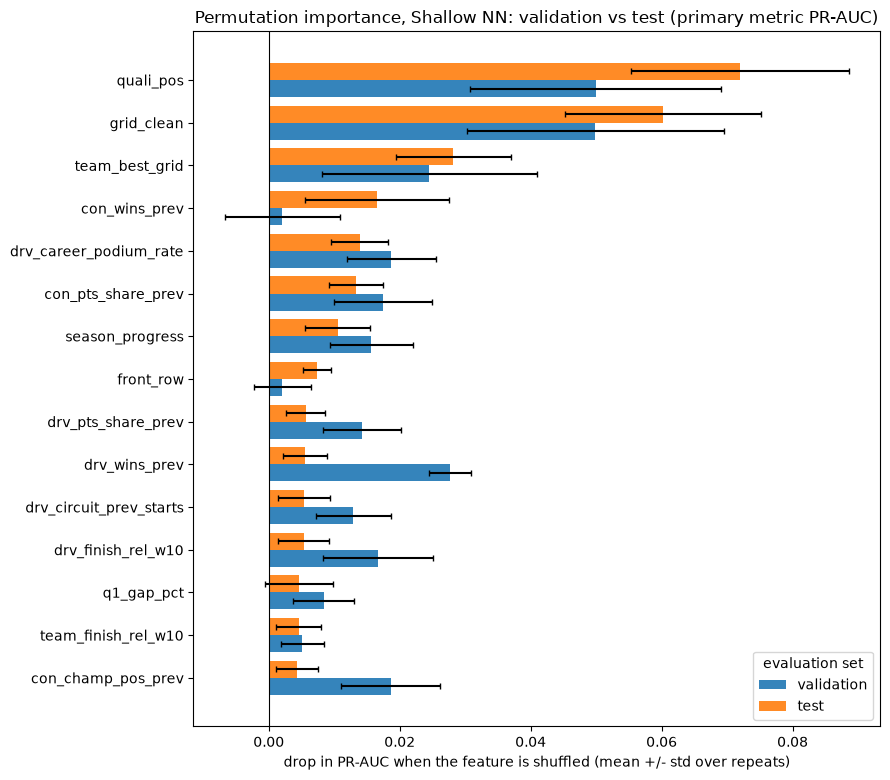

Rank agreement validation vs test: Spearman over all 29 features 0.44 | over the top-10 union (14 features) 0.13 | top-10 overlap 6 of 10
Top-5 shared: ['grid_clean', 'quali_pos', 'team_best_grid']


In [13]:
def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name); fig.savefig(path, dpi=150, bbox_inches="tight"); print("Saved figure:", path); plt.show()

def plot_perm(pi_dict, title, fname, metric="pr_auc", top=TOP_K):
    key = f"{metric}_drop"; ref = list(pi_dict.values())[-1]
    order = ref.sort_values(key, ascending=False).head(top)["feature"].tolist()[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * top + 1.6)); h = 0.8 / len(pi_dict)
    for j, (lab, pi) in enumerate(pi_dict.items()):
        s = pi.set_index("feature").loc[order]
        ax.barh(np.arange(len(order)) + (j - (len(pi_dict) - 1) / 2) * h, s[key], h, xerr=s[f"{metric}_std"], capsize=2, label=lab,
                color=[group_colors[group_of[f]] for f in order] if len(pi_dict) == 1 else None, alpha=0.9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"drop in {metric.replace('_', '-').upper()} when the feature is shuffled (mean +/- std over repeats)"); ax.set_title(title)
    if len(pi_dict) > 1: ax.legend(title="evaluation set")
    else:
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for g, c in group_colors.items() if g in {group_of[f] for f in order}],
                  labels=[g for g in group_colors if g in {group_of[f] for f in order}], fontsize=8, loc="lower right")
    fig.tight_layout(); return fig

save_fig(plot_perm(PI, f"Permutation importance, {LABEL[EXPLAIN_KEY]}: validation vs test (primary metric PR-AUC)", "perm_importance_val_test.png"), "perm_importance_val_test.png")

# do the two evaluation sets agree on the ranking?
AG_VT = agreement(PI["validation"].set_index("feature")["pr_auc_drop"], PI["test"].set_index("feature")["pr_auc_drop"])
print(f"Rank agreement validation vs test: Spearman over all {len(FEATURES)} features {AG_VT['spearman_all']:.2f} | over the top-10 union ({AG_VT['n_union']} features) {AG_VT['spearman_top']:.2f} | top-10 overlap {AG_VT['overlap_top']} of 10")
top_v, top_t = (set(PI[s].sort_values("pr_auc_drop", ascending=False).head(5)["feature"]) for s in ("validation", "test"))
print(f"Top-5 shared: {sorted(top_v & top_t)}")

### 15.3.1 Feature groups (shuffling a whole group at once)

Single-feature importance understates features that have close substitutes. Here every column of a group is shuffled with the **same row permutation** (so the group stays internally consistent but is decoupled from the target and from the other groups). This is the explanation-side counterpart of the feature-group ablation: permutation measures how much the *fitted* model uses a group, ablation measures how much a model *retrained* without the group loses. They can disagree, because a retrained model can compensate with other groups.

,group,n_features,pr_auc_drop,pr_auc_std,roc_auc_drop,roc_auc_std,sum_of_single_feature_drops,group_minus_sum
0,grid,6,0.1780,0.0229,0.0714,0.0081,0.0981,0.0799
1,standings,6,0.0797,0.0143,0.0191,0.0031,0.0445,0.0352
2,qualifying,4,0.0717,0.0139,0.0229,0.0071,0.0803,-0.0086
3,context,4,0.0115,0.0075,0.0003,0.0021,0.0136,-0.0021
4,constructor_form,2,0.0112,0.0066,0.0097,0.0027,0.0073,0.0039
5,driver_form,4,0.0103,0.0075,0.0116,0.0033,0.0243,-0.0140
6,circuit_history,3,-0.0063,0.0066,-0.0020,0.0020,0.0047,-0.0110


group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_groups.png


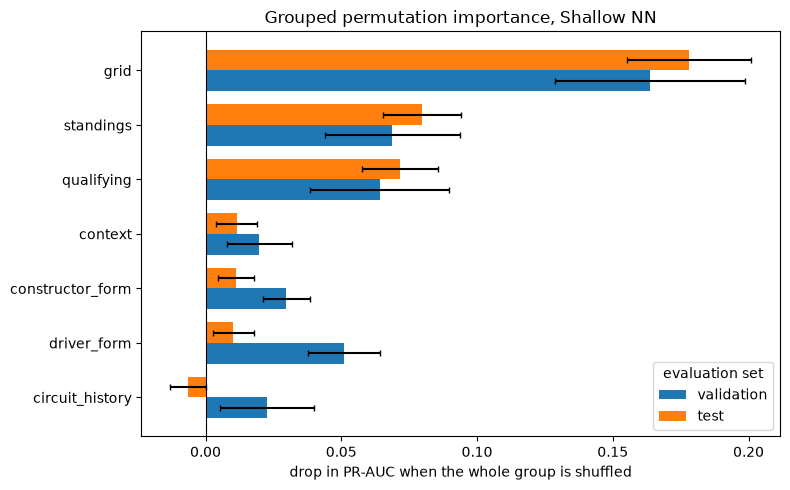

In [14]:
def grouped_perm(m, d, groups, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed); race = d["raceId"].to_numpy(); y = d[TARGET].to_numpy()
    X0 = d[FEATURES]
    score = lambda X: (average_precision_score(y, m.predict_proba(X)[:, 1]), roc_auc_score(y, m.predict_proba(X)[:, 1]))
    b_pr, b_roc = score(X0); rows = []
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X0.copy(); perm = rng.permutation(len(d)); Xp[cols] = X0[cols].to_numpy()[perm]
            pr, roc = score(Xp); drops.append((b_pr - pr, b_roc - roc))
        drops = np.array(drops)
        rows.append(dict(group=g, n_features=len(cols), pr_auc_drop=drops[:, 0].mean(), pr_auc_std=drops[:, 0].std(),
                         roc_auc_drop=drops[:, 1].mean(), roc_auc_std=drops[:, 1].std()))
    return pd.DataFrame(rows).sort_values("pr_auc_drop", ascending=False).reset_index(drop=True)

GPI = {sp: grouped_perm(model, d, FEATURE_GROUPS) for sp, d in (("validation", val), ("test", test))}
single_sum = PI["test"].groupby("group")["pr_auc_drop"].sum()
g_tab = GPI["test"].assign(sum_of_single_feature_drops=lambda t: t["group"].map(single_sum))
g_tab["group_minus_sum"] = g_tab["pr_auc_drop"] - g_tab["sum_of_single_feature_drops"]
GROUP_PI_TABLE = g_tab
display(g_tab.round(4))
print("group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).")

fig, ax = plt.subplots(figsize=(8, 0.5 * len(FEATURE_GROUPS) + 1.5)); h = 0.38
order = GPI["test"].sort_values("pr_auc_drop")["group"].tolist()
for j, sp in enumerate(["validation", "test"]):
    s = GPI[sp].set_index("group").loc[order]
    ax.barh(np.arange(len(order)) + (j - 0.5) * h, s["pr_auc_drop"], h, xerr=s["pr_auc_std"], capsize=2, label=sp)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(title="evaluation set")
ax.set_xlabel("drop in PR-AUC when the whole group is shuffled"); ax.set_title(f"Grouped permutation importance, {LABEL[EXPLAIN_KEY]}")
fig.tight_layout(); save_fig(fig, "perm_importance_groups.png")

### 15.3.2 The same analysis for every verified model

If the same features come out on top for a linear model, a forest, boosting and a network, the finding is about the data and less about one fitted model. The identical permutation protocol is run on **every model that passed the verification in 15.1**, on both validation and test rows (the explained model keeps its full repeat count).

permutation importance for 4 verified models in 77s: ['Logistic regression', 'Shallow NN', 'Random forest', 'XGBoost']
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_cross_model.png


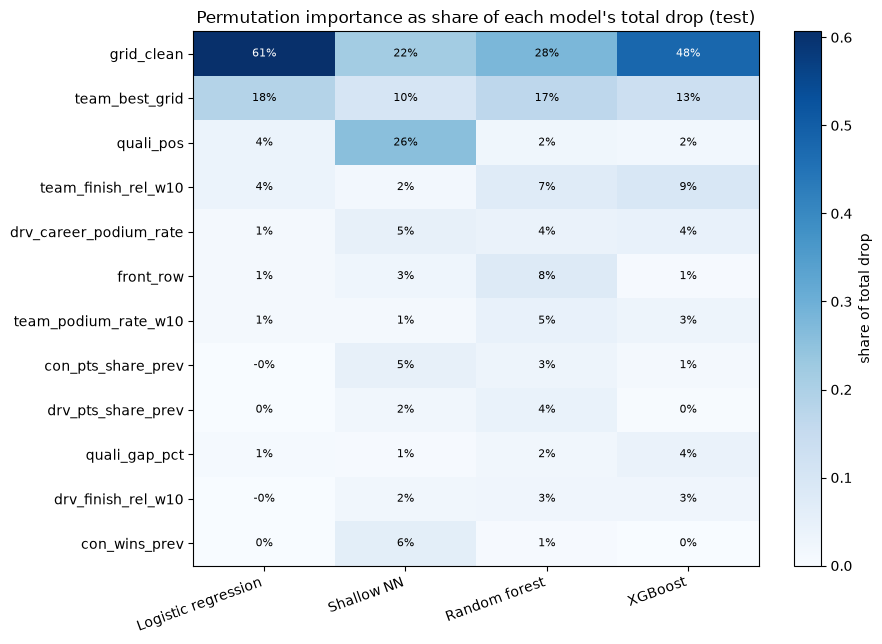

,model,test_pr_auc,reliably_used_features,top3_by_permutation,top_group
0,Logistic regression,0.7182,3,"grid_clean, team_best_grid, team_finish_rel_w10",grid
1,Shallow NN,0.6888,8,"quali_pos, grid_clean, team_best_grid",grid
2,Random forest,0.7176,6,"grid_clean, team_best_grid, front_row",grid
3,XGBoost,0.7152,3,"grid_clean, team_best_grid, team_finish_rel_w10",grid


Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):


,Logistic regression,Shallow NN,Random forest,XGBoost
Logistic regression,1.00,0.20,0.37,0.37
Shallow NN,0.20,1.00,0.02,-0.07
Random forest,0.37,0.02,1.00,0.25
XGBoost,0.37,-0.07,0.25,1.00


Pairwise number of shared features in the top 10:


,Logistic regression,Shallow NN,Random forest,XGBoost
Logistic regression,10,6,6,6
Shallow NN,6,10,6,3
Random forest,6,6,10,5
XGBoost,6,3,5,10


Shallow NN vs the other verified models: Logistic regression 0.20 (top-10 overlap 6), Random forest 0.02 (top-10 overlap 6), XGBoost -0.07 (top-10 overlap 3)


In [15]:
PI_ALL = {}                                   # key -> {"validation": table, "test": table}
t0 = time.time()
for key, m in MODELS.items():
    if key == EXPLAIN_KEY: PI_ALL[key] = PI
    else: PI_ALL[key] = {sp: perm_importance(m, d, n_repeats=N_REPEATS_CROSS) for sp, d in (("validation", val), ("test", test))}
print(f"permutation importance for {len(MODELS)} verified models in {time.time()-t0:.0f}s: {[LABEL[k] for k in MODELS]}")

cross_mat = pd.DataFrame({LABEL[k]: v["test"].set_index("feature")["pr_auc_drop"] for k, v in PI_ALL.items()}).loc[FEATURES]
cross_val = pd.DataFrame({LABEL[k]: v["validation"].set_index("feature")["pr_auc_drop"] for k, v in PI_ALL.items()}).loc[FEATURES]
top_feats = cross_mat.mean(axis=1).sort_values(ascending=False).head(12).index.tolist()
share = cross_mat / cross_mat.clip(lower=0).sum()          # each model's importances as a share of its own total drop
fig, ax = plt.subplots(figsize=(1.3 * len(cross_mat.columns) + 4, 0.42 * len(top_feats) + 1.5))
im = ax.imshow(share.loc[top_feats].to_numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=20, ha="right"); ax.set_yticks(range(len(top_feats))); ax.set_yticklabels(top_feats)
for (i, j), v in np.ndenumerate(share.loc[top_feats].to_numpy()): ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > share.loc[top_feats].to_numpy().max() * 0.6 else "black")
ax.set_title("Permutation importance as share of each model's total drop (test)"); plt.colorbar(im, label="share of total drop"); fig.tight_layout()
save_fig(fig, "perm_importance_cross_model.png")

summ = []
for k in MODELS:
    t = PI_ALL[k]["test"].sort_values("pr_auc_drop", ascending=False)
    summ.append(dict(model=LABEL[k], test_pr_auc=check[(check["key"] == k) & (check["split"] == "test")]["pr_auc"].iloc[0], reliably_used_features=int(t["reliable"].sum()),
                     top3_by_permutation=", ".join(t.head(3)["feature"]), top_group=pd.Series(PI_ALL[k]["test"].groupby("group")["pr_auc_drop"].sum()).idxmax()))
display(pd.DataFrame(summ).round(4))

cols_ = list(cross_mat.columns)
rank_corr = pd.DataFrame([[agreement(cross_mat[a], cross_mat[b_])["spearman_top"] for b_ in cols_] for a in cols_], index=cols_, columns=cols_)
overlap = pd.DataFrame([[agreement(cross_mat[a], cross_mat[b_])["overlap_top"] for b_ in cols_] for a in cols_], index=cols_, columns=cols_)
print("Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):"); display(rank_corr.round(2))
print("Pairwise number of shared features in the top 10:"); display(overlap)
others = [c for c in rank_corr.columns if c != LABEL[EXPLAIN_KEY]]
if others:
    print(f"{LABEL[EXPLAIN_KEY]} vs the other verified models: " + ", ".join(f"{c} {rank_corr.loc[LABEL[EXPLAIN_KEY], c]:.2f} (top-10 overlap {overlap.loc[LABEL[EXPLAIN_KEY], c]})" for c in others))

## 15.4 Does the explanation depend on the random seed of the network?

A network started from a different random seed can reach a similar score through different internal weights. The neural-network notebook saw validation PR-AUC move between seeds, so the explanation could also move. The saved network is retrained with three seeds using the identical recipe (train rows only, early stopping on validation), and the permutation importance rankings are compared. High rank agreement means the explanation is a property of the data and features; low agreement means the explanation of one network should be reported with that caveat. This section only runs when the explained model is the shallow network.

3 retrained networks in 26s


,seed,val_pr_auc,test_pr_auc
0,42,0.7479,0.6888
1,43,0.7363,0.6795
2,44,0.7340,0.6874


Reproduction check: retraining with seed 42 gives validation PR-AUC 0.7479; the saved model's is 0.7479 (identical).


,pair,spearman_all,spearman_top,overlap_top,k,n_union
0,seed 42 vs seed 43,0.63,0.51,7,10,13
1,seed 42 vs seed 44,0.41,0.42,6,10,14
2,seed 42 vs saved model,1.00,1.00,10,10,10
3,seed 43 vs seed 44,0.38,0.49,7,10,13
4,seed 43 vs saved model,0.63,0.51,7,10,13
5,seed 44 vs saved model,0.41,0.42,6,10,14


Top-5 features per run: {'seed 42': ['con_wins_prev', 'drv_career_podium_rate', 'grid_clean', 'quali_pos', 'team_best_grid'], 'seed 43': ['front_row', 'grid_clean', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10'], 'seed 44': ['con_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid', 'team_podium_rate_w10'], 'saved model': ['con_wins_prev', 'drv_career_podium_rate', 'grid_clean', 'quali_pos', 'team_best_grid']}
Features in the top 5 of every run: ['grid_clean', 'quali_pos', 'team_best_grid'] (3 of 5)
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_seeds.png


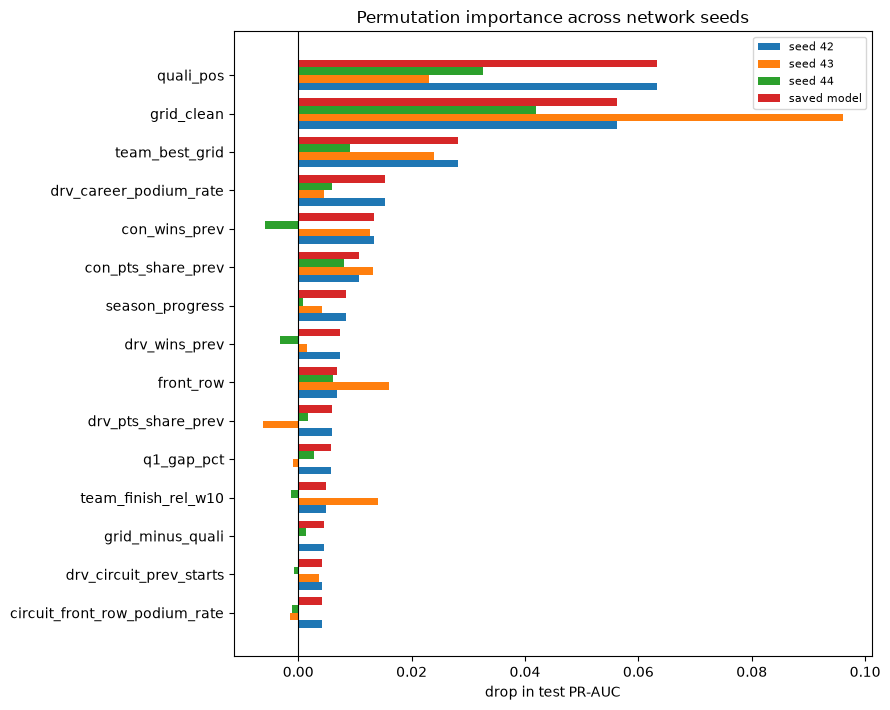

In [16]:
SEED_RANK, SEED_AGREE = None, None
if RUN_SEED_CHECK and EXPLAIN_KEY == "nn":
    prm = META["nn"]["params"]; seed_pi, seed_rows = {}, []
    t0 = time.time()
    for s in [SEED, SEED + 1, SEED + 2]:
        net_s, best_val = train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=s)
        seed_pi[s] = perm_importance(net_s, test, n_repeats=N_REPEATS_CROSS)
        seed_rows.append(dict(seed=s, val_pr_auc=best_val, test_pr_auc=average_precision_score(test[TARGET], predict_p(net_s, test))))
    saved_pi = perm_importance(model, test, n_repeats=N_REPEATS_CROSS)     # same number of repeats as the retrained runs
    print(f"3 retrained networks in {time.time()-t0:.0f}s")
    display(pd.DataFrame(seed_rows).round(4))
    saved_val = META["nn"].get("val", {}).get("pr_auc")
    if saved_val is not None:
        print(f"Reproduction check: retraining with seed {SEED} gives validation PR-AUC {seed_rows[0]['val_pr_auc']:.4f}; the saved model's is {saved_val:.4f} "
              f"({'identical' if abs(seed_rows[0]['val_pr_auc'] - saved_val) < 1e-4 else 'different: library versions or row order differ from the training environment'}).")
    SEED_RANK = pd.DataFrame({f"seed {s}": v.set_index("feature")["pr_auc_drop"] for s, v in seed_pi.items()})
    SEED_RANK["saved model"] = saved_pi.set_index("feature")["pr_auc_drop"]
    pair_rows = [dict(pair=f"{a} vs {b_}", **agreement(SEED_RANK[a], SEED_RANK[b_])) for a, b_ in itertools.combinations(SEED_RANK.columns, 2)]
    SEED_AGREE = pd.DataFrame(pair_rows); display(SEED_AGREE.round(2))
    tops = {c: set(SEED_RANK[c].sort_values(ascending=False).head(5).index) for c in SEED_RANK.columns}
    common = set.intersection(*tops.values())
    print("Top-5 features per run:", {c: sorted(v) for c, v in tops.items()})
    print(f"Features in the top 5 of every run: {sorted(common)} ({len(common)} of 5)")
    fig, ax = plt.subplots(figsize=(9, 0.38 * TOP_K + 1.5)); order = SEED_RANK["saved model"].sort_values(ascending=False).head(TOP_K).index[::-1]
    cols = list(SEED_RANK.columns); h = 0.8 / len(cols)
    for j, c in enumerate(cols): ax.barh(np.arange(len(order)) + (j - (len(cols) - 1) / 2) * h, SEED_RANK.loc[order, c], h, label=c)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(fontsize=8)
    ax.set_xlabel("drop in test PR-AUC"); ax.set_title("Permutation importance across network seeds"); fig.tight_layout(); save_fig(fig, "perm_importance_seeds.png")
else:
    print("Seed check skipped (RUN_SEED_CHECK is off or the explained model is not the shallow network).")

## 15.5 Global explanation 2: SHAP

SHAP assigns each feature a signed contribution to every single prediction, such that **reference average + sum of contributions = the model's score for that row** (checked numerically below). Averaging the absolute contributions over rows gives a global importance; plotting the signed contributions against the feature value shows the direction and shape of the model's reliance.

The model is a neural network behind a preprocessing pipeline, so the model-agnostic **permutation explainer** is used, applied to the *raw 29 features* (the pipeline's imputation and missing indicators are part of the function being explained). It is run on every test row, with 100 hybrid-era training rows as the reference.

In [17]:
# ---- reference data, explainer and SHAP values for every test row ------------------------------------------------
bg_pool = train[train["year"] >= BACKGROUND_FROM_YEAR]
if len(bg_pool) < 300:
    print(f"only {len(bg_pool)} training rows from {BACKGROUND_FROM_YEAR}; using validation rows as the reference instead"); bg_pool = val
bg_df = bg_pool.sample(min(BACKGROUND_SIZE, len(bg_pool)), random_state=SEED)[FEATURES]
bg_arr = bg_df.to_numpy(float)
print(f"reference data: {len(bg_df)} rows sampled from {len(bg_pool):,} training rows of seasons {int(bg_pool['year'].min())}-{int(bg_pool['year'].max())}")

def xai_proba(X): return model.predict_proba(pd.DataFrame(X, columns=FEATURES))
def xai_f(X): return xai_proba(X)[:, 1]

ex = (test if N_EXPLAIN is None else test.sample(min(N_EXPLAIN, len(test)), random_state=SEED)).reset_index(drop=True)
X_ex = ex[FEATURES].to_numpy(float)

def run_shap(bg, X, n_perm=N_PERMUTATIONS):
    masker = shap.maskers.Independent(bg, max_samples=len(bg))
    explainer = shap.explainers.Permutation(xai_f, masker, feature_names=FEATURES, seed=SEED)
    return explainer(X, max_evals=2 * len(FEATURES) * n_perm + 1, silent=True)

t0 = time.time()
sv = run_shap(bg_arr, X_ex)
sv.feature_names = list(FEATURES)
p_ex = xai_f(X_ex)
add_err = float(np.abs(sv.values.sum(1) + sv.base_values - p_ex).max())
print(f"SHAP for {len(ex):,} rows x {len(FEATURES)} features in {time.time()-t0:.0f}s")
print(f"additivity check, max |base + sum(SHAP) - model score| = {add_err:.2e}")
assert add_err < 1e-6, "SHAP values do not add up to the model output"
base_val = float(np.mean(sv.base_values))
print(f"reference average score (SHAP base value) = {base_val:.3f}  vs true podium rate in test = {ex[TARGET].mean():.3f} "
      f"(the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)")

shap_tab = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES],
                         "mean_abs_shap": np.abs(sv.values).mean(0), "mean_shap": sv.values.mean(0)}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_tab["share_of_total"] = shap_tab["mean_abs_shap"] / shap_tab["mean_abs_shap"].sum()
display(shap_tab.head(TOP_K).round(4))

reference data: 100 rows sampled from 2,470 training rows of seasons 2014-2019
SHAP for 1,351 rows x 29 features in 79s
additivity check, max |base + sum(SHAP) - model score| = 4.89e-10
reference average score (SHAP base value) = 0.346  vs true podium rate in test = 0.151 (the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)


,feature,group,mean_abs_shap,mean_shap,share_of_total
0,grid_clean,grid,0.0595,-0.0128,0.1085
1,quali_pos,qualifying,0.0591,-0.0131,0.1078
2,team_best_grid,grid,0.0477,-0.0066,0.0870
3,drv_pts_share_prev,standings,0.0334,-0.0031,0.0609
4,drv_podium_rate_w10,driver_form,0.0322,-0.0037,0.0588
5,quali_gap_pct,qualifying,0.0281,0.0132,0.0512
6,drv_career_podium_rate,driver_form,0.0270,-0.0064,0.0492
7,con_wins_prev,standings,0.0259,-0.0051,0.0473
8,drv_champ_pos_prev,standings,0.0231,-0.0004,0.0422
9,team_podium_rate_w10,constructor_form,0.0226,-0.0032,0.0412


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_bar.png


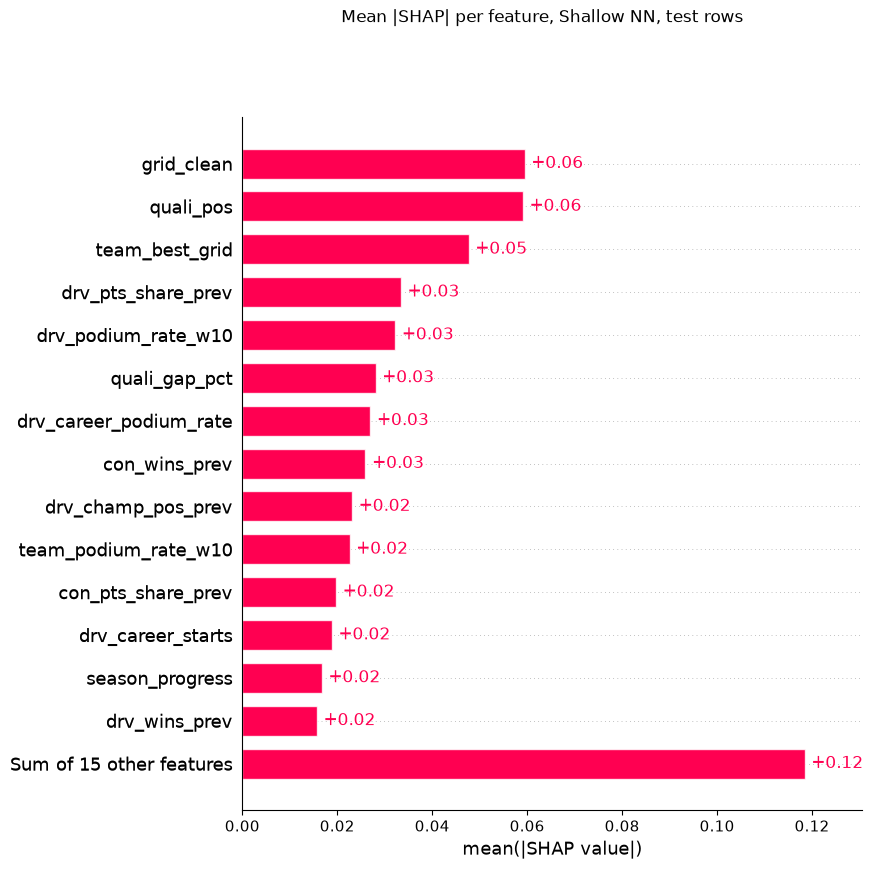

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm.png


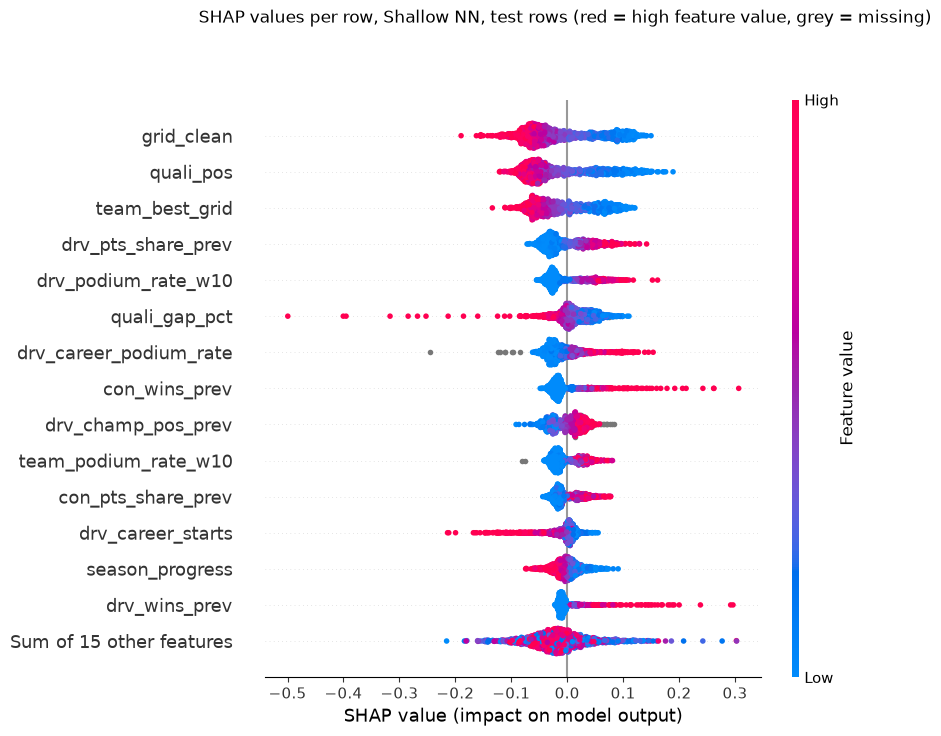

In [18]:
# bar (mean |SHAP|) and beeswarm (signed SHAP coloured by feature value; grey = missing value)
plt.figure(); shap.plots.bar(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"Mean |SHAP| per feature, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); save_fig(fig, "shap_bar.png")
plt.figure(); shap.plots.beeswarm(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"SHAP values per row, {LABEL[EXPLAIN_KEY]}, test rows (red = high feature value, grey = missing)", y=1.0); save_fig(fig, "shap_beeswarm.png")

### 15.5.1 Group SHAP

SHAP values are additive, so the contribution of a feature group to a row is simply the sum of its members' values. This is immune to the credit-splitting problem between correlated features inside a group, and it matches the grouping used by the ablation.

,group,n_features,mean_abs_group_shap,mean_signed,share_of_total
0,grid,6,0.1119,-0.0222,0.2922
1,qualifying,4,0.0755,-0.0083,0.1972
2,standings,6,0.0671,-0.0130,0.1754
3,driver_form,4,0.0525,-0.0158,0.1370
4,constructor_form,2,0.0367,-0.0043,0.0959
5,context,4,0.0210,-0.0022,0.0548
6,circuit_history,3,0.0182,-0.0026,0.0475


C:\Users\moham\AppData\Local\Temp\ipykernel_32292\2688108765.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  try: axes[1].boxplot([G[g] for g in order], vert=False, tick_labels=order, showfliers=False)


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_groups.png


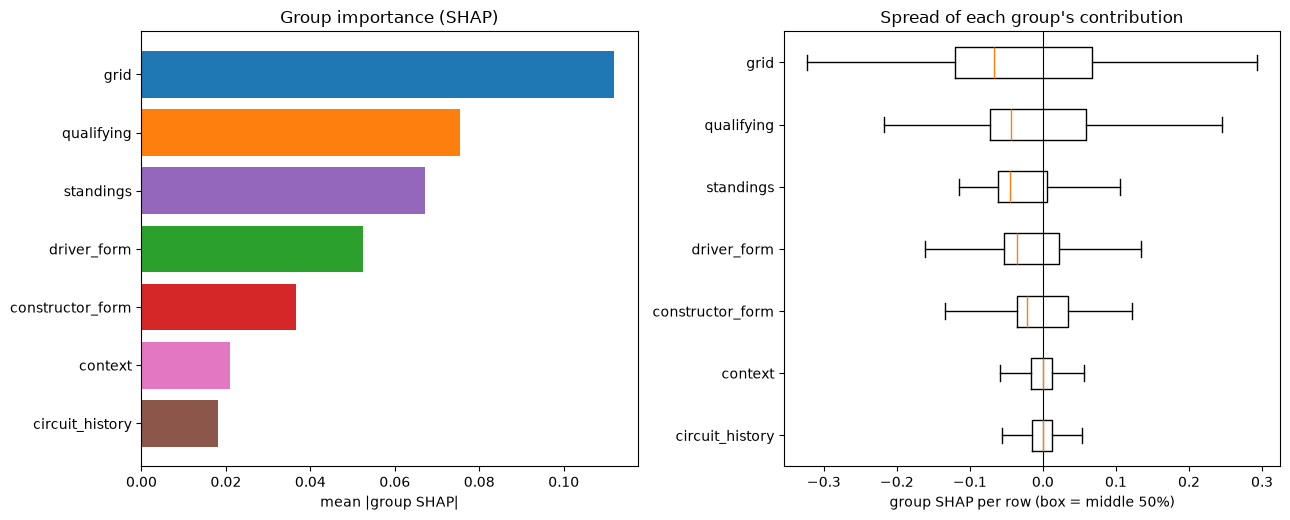

In [19]:
gidx = {g: [FEATURES.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}
G = pd.DataFrame({g: sv.values[:, ix].sum(1) for g, ix in gidx.items()})
group_shap = pd.DataFrame({"group": list(G.columns), "n_features": [len(FEATURE_GROUPS[g]) for g in G.columns],
                           "mean_abs_group_shap": G.abs().mean().values, "mean_signed": G.mean().values}).sort_values("mean_abs_group_shap", ascending=False).reset_index(drop=True)
group_shap["share_of_total"] = group_shap["mean_abs_group_shap"] / group_shap["mean_abs_group_shap"].sum()
display(group_shap.round(4))
order = group_shap.sort_values("mean_abs_group_shap")["group"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.5 * len(order) + 1.8))
axes[0].barh(order, group_shap.set_index("group").loc[order, "mean_abs_group_shap"], color=[group_colors[g] for g in order])
axes[0].set_xlabel("mean |group SHAP|"); axes[0].set_title("Group importance (SHAP)")
try: axes[1].boxplot([G[g] for g in order], vert=False, tick_labels=order, showfliers=False)
except TypeError: axes[1].boxplot([G[g] for g in order], vert=False, labels=order, showfliers=False)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("group SHAP per row (box = middle 50%)"); axes[1].set_title("Spread of each group's contribution")
fig.tight_layout(); save_fig(fig, "shap_groups.png")

### 15.5.2 Dependence plots for the four most important features

Each dot is one test row. The vertical axis is how much the feature moved that row's score; colour is the feature that interacts most with it (chosen automatically). These show the *shape* of the model's reliance, for example whether the effect of the starting slot is a smooth decline or a cliff after the front rows. They describe the model, not the sport.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_dependence_top4.png


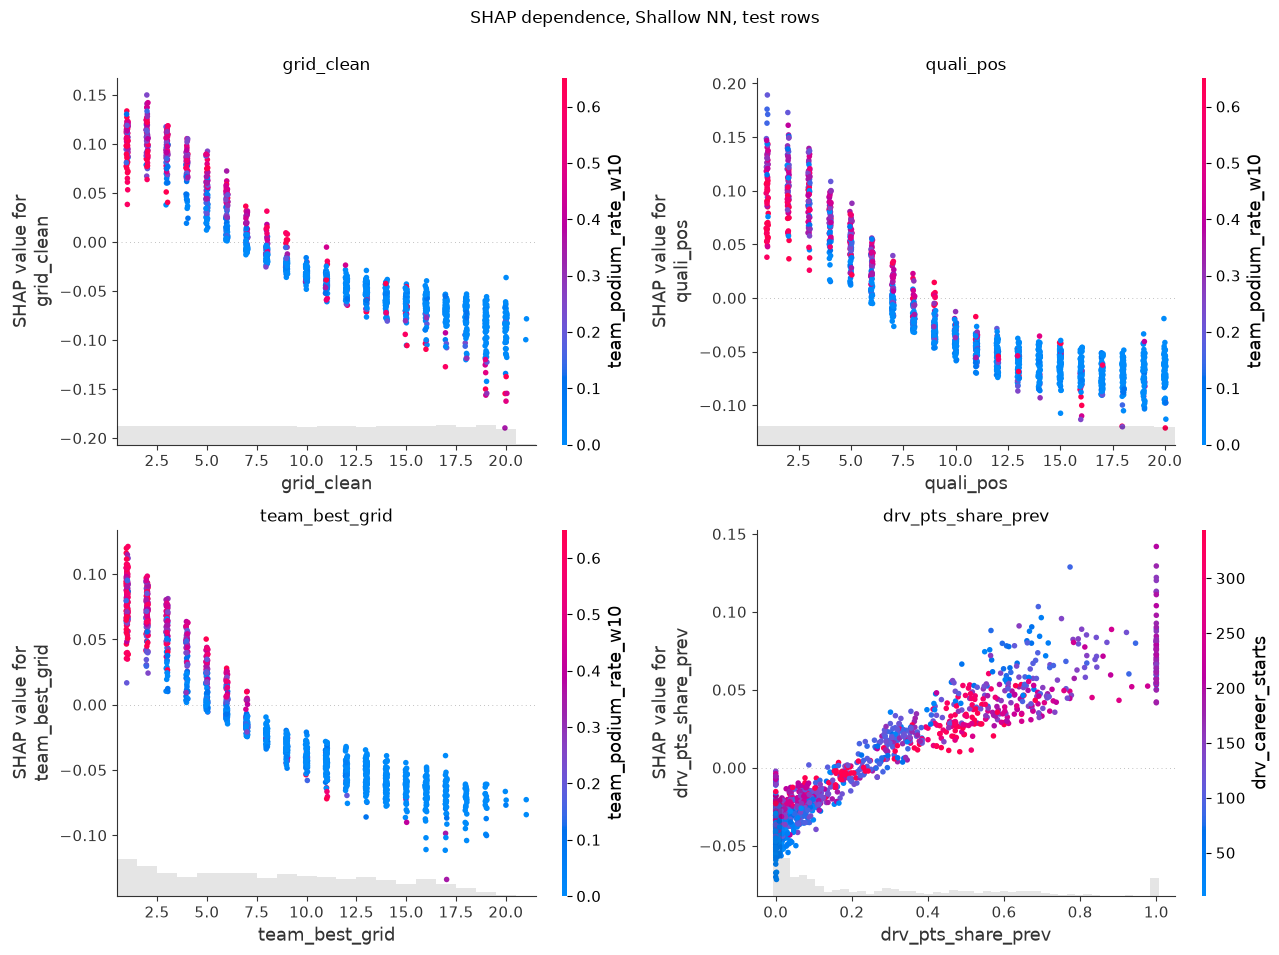

In [20]:
top4 = shap_tab.head(4)["feature"].tolist()
try:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
    for ax, f in zip(axes.ravel(), top4):
        shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False); ax.set_title(f)
    fig.suptitle(f"SHAP dependence, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); fig.tight_layout(); save_fig(fig, "shap_dependence_top4.png")
except TypeError:      # older shap versions have no ax= argument: one figure per feature
    plt.close("all")
    for f in top4:
        plt.figure(); shap.plots.scatter(sv[:, f], color=sv, show=False); save_fig(plt.gcf(), f"shap_dependence_{f}.png")

### 15.5.3 Do permutation importance and SHAP tell the same story?

They measure different things: permutation importance is the **loss in performance** from destroying a feature; mean |SHAP| is the **average size of the feature's push** on predictions, whether or not the push is right. A feature can move scores a lot and still add little accuracy (a noisy feature the model leans on), so disagreement is informative, not an error.

Permutation vs SHAP: Spearman over all 29 features 0.60 | over the top-10 union (14 features) 0.42 | top-10 overlap 6 of 10 | top-5 shared: ['grid_clean', 'quali_pos', 'team_best_grid']


,perm_pr_auc_drop,mean_abs_shap,perm_rank,shap_rank,rank_gap
feature,,,,,
grid_clean,0.0602,0.0595,2,1,1
quali_pos,0.0719,0.0591,1,2,-1
team_best_grid,0.0282,0.0477,3,3,0
drv_pts_share_prev,0.0056,0.0334,9,4,5
drv_podium_rate_w10,0.0026,0.0322,20,5,15
quali_gap_pct,0.0015,0.0281,23,6,17
drv_career_podium_rate,0.0139,0.0270,5,7,-2
con_wins_prev,0.0166,0.0259,4,8,-4
drv_champ_pos_prev,-0.0008,0.0231,27,9,18


Features whose two ranks differ by 8 places or more: {'front_row': (8, 22), 'pole': (16, 26), 'drv_finish_rel_w10': (12, 21), 'team_podium_rate_w10': (18, 10), 'drv_podium_rate_w10': (20, 5), 'quali_gap_pct': (23, 6), 'drv_champ_pos_prev': (27, 9)}
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_vs_shap.png


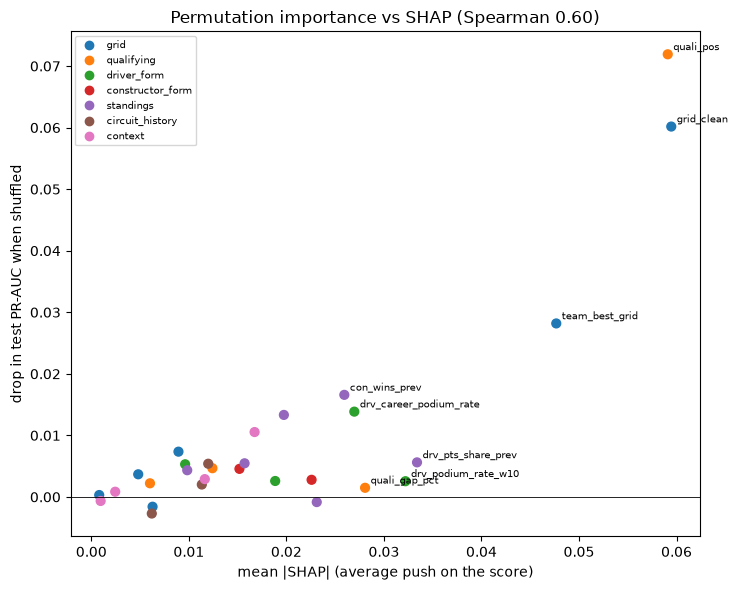

In [21]:
cmp = pd.DataFrame({"perm_pr_auc_drop": PI["test"].set_index("feature")["pr_auc_drop"],
                    "mean_abs_shap": shap_tab.set_index("feature")["mean_abs_shap"]}).loc[FEATURES]
cmp["perm_rank"] = cmp["perm_pr_auc_drop"].rank(ascending=False, method="min").astype(int)
cmp["shap_rank"] = cmp["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
cmp["rank_gap"] = cmp["perm_rank"] - cmp["shap_rank"]
AG_PS = agreement(cmp["perm_pr_auc_drop"], cmp["mean_abs_shap"]); rho_ps = AG_PS["spearman_all"]
tp, ts = (set(cmp.sort_values(c_, ascending=True).head(5).index) for c_ in ("perm_rank", "shap_rank"))
print(f"Permutation vs SHAP: Spearman over all {len(cmp)} features {AG_PS['spearman_all']:.2f} | over the top-10 union ({AG_PS['n_union']} features) {AG_PS['spearman_top']:.2f} | "
      f"top-10 overlap {AG_PS['overlap_top']} of 10 | top-5 shared: {sorted(tp & ts)}")
display(cmp.sort_values("shap_rank").head(TOP_K).round(4))
big_gap = cmp[cmp["rank_gap"].abs() >= 8].sort_values("rank_gap")
print("Features whose two ranks differ by 8 places or more:", {f: (int(r.perm_rank), int(r.shap_rank)) for f, r in big_gap.iterrows()} or "none")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(cmp["mean_abs_shap"], cmp["perm_pr_auc_drop"], c=[group_colors[group_of[f]] for f in cmp.index], s=40)
for f in cmp.sort_values("shap_rank").head(8).index: ax.annotate(f, (cmp.loc[f, "mean_abs_shap"], cmp.loc[f, "perm_pr_auc_drop"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("mean |SHAP| (average push on the score)"); ax.set_ylabel("drop in test PR-AUC when shuffled")
ax.set_title(f"Permutation importance vs SHAP (Spearman {rho_ps:.2f})")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in group_colors.items()], fontsize=7); fig.tight_layout(); save_fig(fig, "perm_vs_shap.png")

## 15.6 Sensitivity checks

### 15.6.1 How much does the SHAP reference data matter?

The same explanation is recomputed on a random 300-row subset of the test rows with three different reference samples: the default (hybrid-era training rows), a random sample of **all** training eras, and the validation rows. If the importance ranking barely moves, the reference choice is not driving the conclusions; the base value will move, because it is the average score of the reference.

In [22]:
sub_pos = np.random.default_rng(SEED).choice(len(ex), size=min(300, len(ex)), replace=False)
X_sub = X_ex[sub_pos]
BG = {"hybrid-era train (default)": bg_arr,
      "all-era train (random)": train.sample(min(BACKGROUND_SIZE, len(train)), random_state=SEED)[FEATURES].to_numpy(float),
      "validation": val.sample(min(BACKGROUND_SIZE, len(val)), random_state=SEED)[FEATURES].to_numpy(float)}
bg_imp, bg_base = {}, {}
t0 = time.time()
for name, b in BG.items():
    s_ = run_shap(b, X_sub); bg_imp[name] = np.abs(s_.values).mean(0); bg_base[name] = float(s_.base_values.mean())
print(f"3 reference choices on {len(X_sub)} rows in {time.time()-t0:.0f}s")
bg_imp = pd.DataFrame(bg_imp, index=FEATURES)
display(pd.Series(bg_base, name="base value (average score of the reference)").round(3).to_frame())
display(bg_imp.corr(method="spearman").round(3))
bg_tops = {c: set(bg_imp[c].sort_values(ascending=False).head(5).index) for c in bg_imp.columns}
print("Top-5 features per reference:", {c: sorted(v) for c, v in bg_tops.items()})
print(f"In the top 5 under every reference: {sorted(set.intersection(*bg_tops.values()))}")
BG_MIN_RHO = float(bg_imp.corr(method="spearman").to_numpy()[np.triu_indices(len(BG), 1)].min())

3 reference choices on 300 rows in 50s


,base value (average score of the reference)
hybrid-era train (default),0.346
all-era train (random),0.314
validation,0.249


,hybrid-era train (default),all-era train (random),validation
hybrid-era train (default),1.000,0.858,0.979
all-era train (random),0.858,1.000,0.863
validation,0.979,0.863,1.000


Top-5 features per reference: {'hybrid-era train (default)': ['drv_podium_rate_w10', 'drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid'], 'all-era train (random)': ['drv_pts_share_prev', 'grid_clean', 'q1_gap_pct', 'quali_pos', 'team_best_grid'], 'validation': ['drv_podium_rate_w10', 'drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid']}
In the top 5 under every reference: ['drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid']


### 15.6.2 Exact SHAP for every other verified model

The logistic regression, random forest and XGBoost have exact SHAP algorithms (linear SHAP and TreeSHAP: no sampling noise). They are applied to the models' **actual inputs** (after imputation, scaling and missing indicators), and the contributions of a feature's missing-indicator column are added back to the feature itself, so the result is again one number per raw feature per row and is directly comparable with the network's. Each result is checked for additivity against the model's own output. Output spaces differ (log-odds for the linear model and XGBoost, probability for the forest and network), so **only rankings and shapes are comparable across models, not magnitudes**.

In [23]:
def transformed_names(pre):
    # raw-feature name of every column the fitted ColumnTransformer outputs (imputed features, then missing indicators, per block)
    names = []
    for nm, trans, cols in pre.transformers_:
        if isinstance(trans, str) and trans == "drop": continue
        cols = list(cols); names += cols
        if isinstance(trans, str): continue                                  # passthrough
        imp = trans.named_steps["imp"] if isinstance(trans, Pipeline) and "imp" in trans.named_steps else trans
        ind = getattr(imp, "indicator_", None)
        if ind is not None: names += [cols[j] for j in ind.features_]
    return names

def exact_shap(m, X_df):
    pre, clf = m.named_steps["pre"], m.named_steps["clf"]
    Xt = np.asarray(pre.transform(X_df), float); names = transformed_names(pre)
    if len(names) != Xt.shape[1]: raise RuntimeError(f"column mapping failed ({len(names)} names for {Xt.shape[1]} columns)")
    if isinstance(clf, LogisticRegression):
        ex_ = shap.LinearExplainer(clf, np.asarray(pre.transform(bg_df), float)); v = ex_.shap_values(Xt)
        ev, ref, space = float(np.ravel(ex_.expected_value)[0]), clf.decision_function(Xt), "log-odds"
    elif isinstance(clf, RandomForestClassifier):
        ex_ = shap.TreeExplainer(clf); v = ex_.shap_values(Xt, check_additivity=False)
        v = v[1] if isinstance(v, list) else (v[..., 1] if np.ndim(v) == 3 else v)
        ev, ref, space = float(np.ravel(ex_.expected_value)[-1]), clf.predict_proba(Xt)[:, 1], "probability"
    elif HAVE_XGB and isinstance(clf, XGBClassifier):
        ex_ = shap.TreeExplainer(clf); v = ex_.shap_values(Xt)
        ev, ref, space = float(np.ravel(ex_.expected_value)[0]), clf.predict(Xt, output_margin=True), "log-odds (margin)"
    else:
        raise NotImplementedError(f"no exact SHAP algorithm wired for {type(clf).__name__}")
    v = np.asarray(v, float)
    raw = pd.DataFrame(v, columns=names).T.groupby(level=0).sum().T[FEATURES]
    return dict(values=raw, space=space, base=ev, add_err=float(np.max(np.abs(ev + raw.sum(axis=1).to_numpy() - ref))))

OTHER_SHAP, rows = {}, []
for key, m in MODELS.items():
    if key == EXPLAIN_KEY: continue
    t0 = time.time()
    try:
        OTHER_SHAP[key] = exact_shap(m, ex[FEATURES])
        o = OTHER_SHAP[key]; rows.append(dict(model=LABEL[key], algorithm="exact", output_space=o["space"], max_additivity_error=o["add_err"], seconds=round(time.time() - t0, 1),
                                              result="OK" if o["add_err"] < 1e-3 else "ADDITIVITY CHECK FAILED"))
        if o["add_err"] >= 1e-3: del OTHER_SHAP[key]
    except Exception as e:
        rows.append(dict(model=LABEL[key], algorithm="-", output_space="-", max_additivity_error=np.nan, seconds=round(time.time() - t0, 1), result=f"not run: {type(e).__name__}: {str(e)[:80]}"))
OTHER_SHAP_STATUS = pd.DataFrame(rows); display(OTHER_SHAP_STATUS)

,model,algorithm,output_space,max_additivity_error,seconds,result
0,Logistic regression,exact,log-odds,2.664535e-15,0.0,OK
1,Random forest,exact,probability,6.772360e-15,11.0,OK
2,XGBoost,exact,log-odds (margin),5.347421e-06,0.2,OK


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_cross_model.png


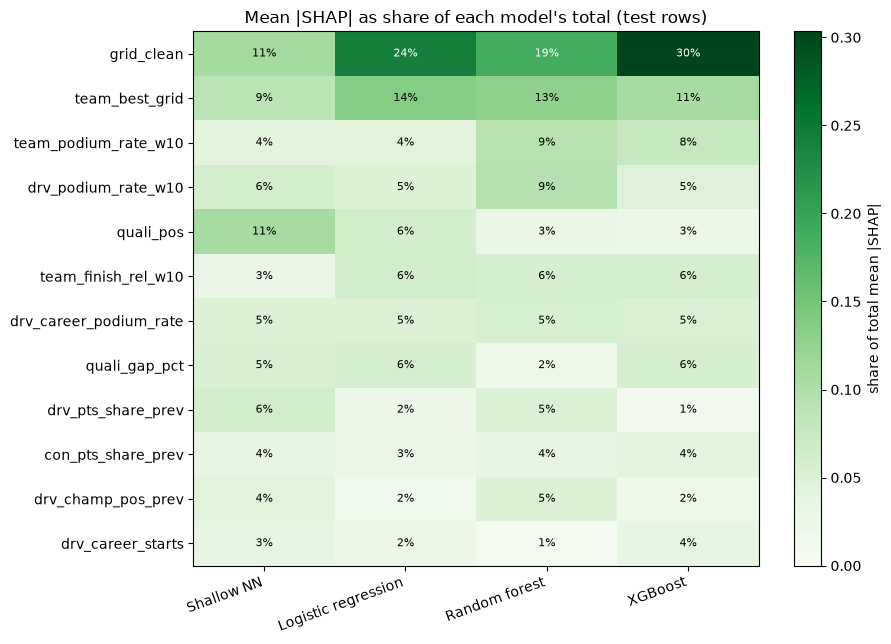

,spearman_all,spearman_top10_union,overlap_top,k,n_union
Logistic regression,0.74,0.52,7.0,10.0,13.0
Random forest,0.74,0.29,7.0,10.0,13.0
XGBoost,0.72,0.17,6.0,10.0,14.0


Permutation importance vs SHAP, within each model:


,model,spearman_top,overlap_top
0,Shallow NN,0.42,6
1,Logistic regression,0.61,7
2,Random forest,0.57,9
3,XGBoost,0.74,8


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm_logreg.png


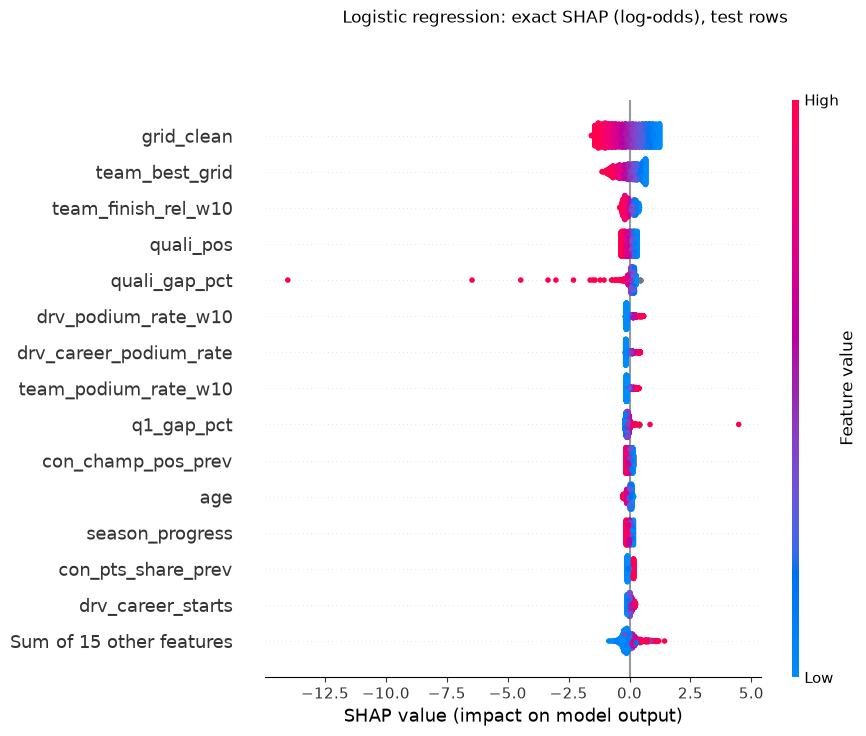

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm_rf.png


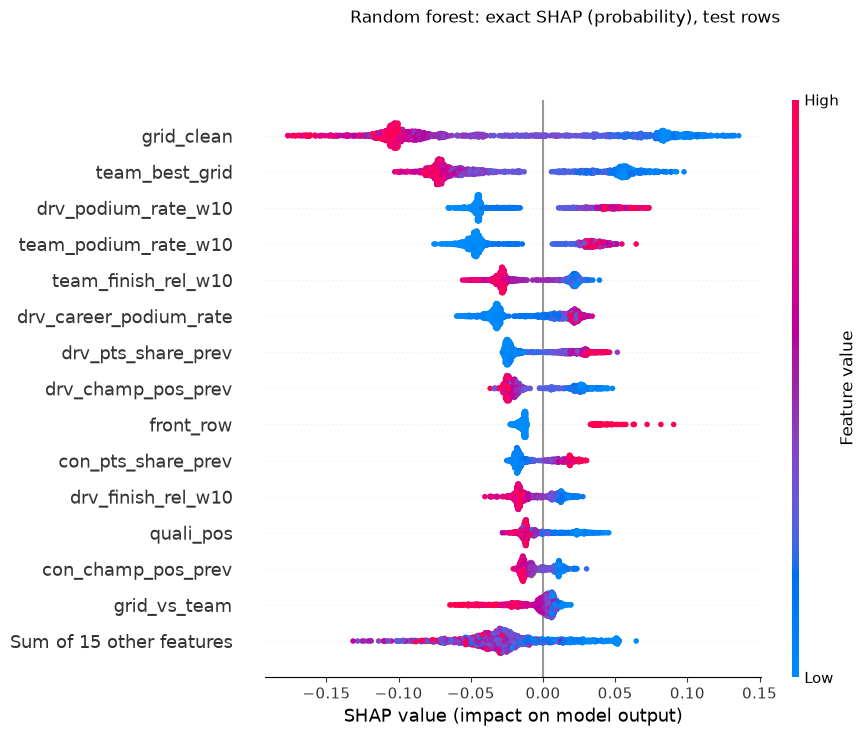

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm_xgb.png


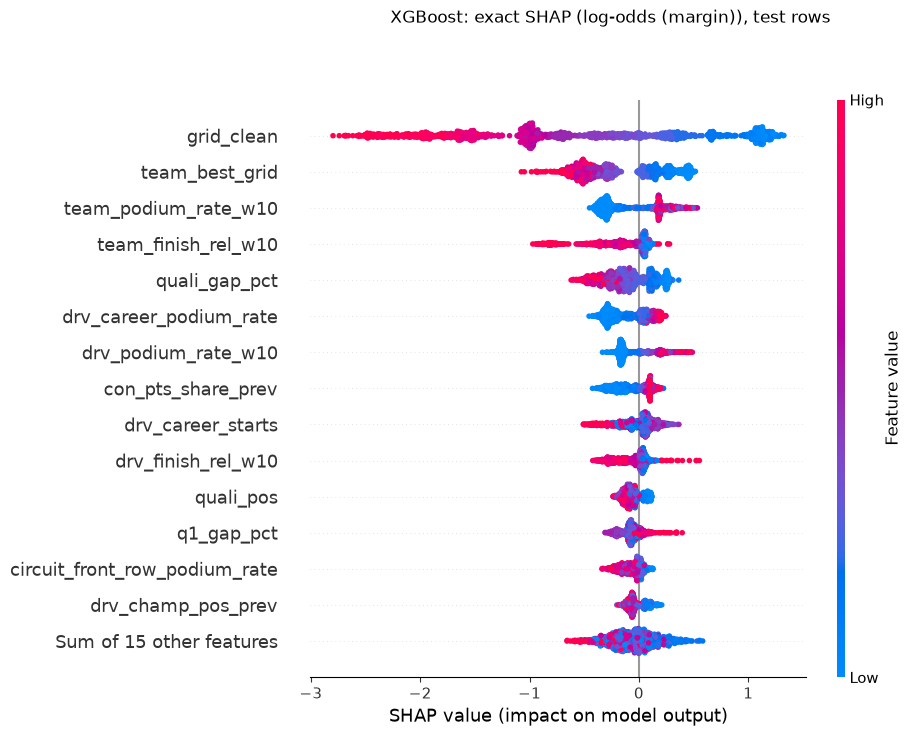

In [24]:
SHAP_CROSS = pd.DataFrame({LABEL[EXPLAIN_KEY]: np.abs(sv.values).mean(0)}, index=FEATURES)
for k, o in OTHER_SHAP.items(): SHAP_CROSS[LABEL[k]] = o["values"].abs().mean().reindex(FEATURES)
AG_OTHERS = {}
if len(SHAP_CROSS.columns) > 1:
    shares = SHAP_CROSS / SHAP_CROSS.sum(); top_s = shares.mean(axis=1).sort_values(ascending=False).head(12).index.tolist()
    fig, ax = plt.subplots(figsize=(1.3 * len(shares.columns) + 4, 0.42 * len(top_s) + 1.5))
    im = ax.imshow(shares.loc[top_s].to_numpy(), cmap="Greens", aspect="auto", vmin=0)
    ax.set_xticks(range(shares.shape[1])); ax.set_xticklabels(shares.columns, rotation=20, ha="right"); ax.set_yticks(range(len(top_s))); ax.set_yticklabels(top_s)
    for (i, j), v in np.ndenumerate(shares.loc[top_s].to_numpy()): ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > shares.loc[top_s].to_numpy().max() * 0.6 else "black")
    ax.set_title("Mean |SHAP| as share of each model's total (test rows)"); plt.colorbar(im, label="share of total mean |SHAP|"); fig.tight_layout(); save_fig(fig, "shap_cross_model.png")
    for c_ in [c for c in SHAP_CROSS.columns if c != LABEL[EXPLAIN_KEY]]: AG_OTHERS[c_] = agreement(SHAP_CROSS[LABEL[EXPLAIN_KEY]], SHAP_CROSS[c_])
    display(pd.DataFrame(AG_OTHERS).T.round(2).rename(columns={"spearman_top": "spearman_top10_union"}))
    # does each model's own permutation ranking agree with its own SHAP ranking?
    ps_rows = [dict(model=c_, **{k: v for k, v in agreement(cross_mat[c_], SHAP_CROSS[c_]).items() if k in ("spearman_top", "overlap_top")}) for c_ in SHAP_CROSS.columns]
    print("Permutation importance vs SHAP, within each model:"); display(pd.DataFrame(ps_rows).round(2))
    for k, o in OTHER_SHAP.items():
        plt.figure(); shap.plots.beeswarm(shap.Explanation(values=o["values"].to_numpy(), data=X_ex, feature_names=FEATURES), max_display=TOP_K, show=False)
        fig = plt.gcf(); fig.suptitle(f"{LABEL[k]}: exact SHAP ({o['space']}), test rows", y=1.0); save_fig(fig, f"shap_beeswarm_{k}.png")
else:
    print("No other verified model with an exact SHAP algorithm: cross-model SHAP comparison skipped.")

## 15.7 Local explanations

Global importance averages over thousands of rows. A local explanation answers "why did the model give *this* driver in *this* race that score?". Four test rows are picked by fixed rules (not by hand), so the selection cannot be accused of cherry-picking flattering cases:

| Case | Rule |
|---|---|
| Confident hit | podium finisher with the highest score (and above the threshold) |
| Missed podium | podium finisher with the lowest score (largest miss) |
| False alarm | non-podium driver with the highest score (largest false alarm) |
| Borderline | the row whose score is closest to the decision threshold |

Each is explained with **local SHAP** (waterfall) and **LIME**. The finishing position and status shown in the table are post-race facts shown only to describe the case; they are never inputs.

In [25]:
thr = THRESHOLD[EXPLAIN_KEY]; y_ex = ex[TARGET].to_numpy()
def pick(mask, how):
    ix = np.where(mask)[0]
    return None if len(ix) == 0 else int(ix[np.argmax(p_ex[ix])] if how == "max" else ix[np.argmin(p_ex[ix])])
CASES = {"Confident hit": pick((y_ex == 1) & (p_ex >= thr), "max"), "Missed podium": pick((y_ex == 1) & (p_ex < thr), "min"),
         "False alarm": pick((y_ex == 0) & (p_ex >= thr), "max"), "Borderline": int(np.argmin(np.abs(p_ex - thr)))}
CASES = {k: v for k, v in CASES.items() if v is not None}

def load_clean(name):
    p = locate(f"{name}.parquet")
    try: return pd.read_parquet(p) if p else None
    except Exception: return None
drivers_t, races_t, cons_t, results_t, status_t = (load_clean(n) for n in ["drivers", "races", "constructors", "results", "status"])
def mapping(t, key, fn):
    if t is None or key not in t.columns: return {}
    return {int(k): v for k, v in zip(pd.to_numeric(t[key], errors="coerce"), t.apply(fn, axis=1)) if not pd.isna(k)}
drv_name = mapping(drivers_t, "driverId", lambda r: f"{r['forename']} {r['surname']}") if drivers_t is not None and "forename" in drivers_t else {}
race_name = mapping(races_t, "raceId", lambda r: f"{int(r['year'])} {r['name']}") if races_t is not None and "name" in races_t else {}
con_name = mapping(cons_t, "constructorId", lambda r: r["name"]) if cons_t is not None and "name" in cons_t else {}
res_info = {}
if results_t is not None and {"resultId", "positionOrder"} <= set(results_t.columns):
    st = {} if status_t is None else dict(zip(pd.to_numeric(status_t["statusId"]), status_t["status"]))
    for r in results_t.itertuples():
        res_info[int(r.resultId)] = (r.positionOrder, st.get(int(r.statusId)) if hasattr(r, "statusId") and not pd.isna(r.statusId) else None)

def case_label(i):
    r = ex.iloc[i]
    return (f"{drv_name.get(int(r['driverId']), 'driver ' + str(int(r['driverId'])))}, "
            f"{race_name.get(int(r['raceId']), 'race ' + str(int(r['raceId'])))}, {con_name.get(int(r['constructorId']), 'team ' + str(int(r['constructorId'])))}")

rows = []
for name, i in CASES.items():
    r = ex.iloc[i]; fin = res_info.get(int(r["resultId"]), (None, None))
    rows.append(dict(case=name, row=case_label(i), score=round(float(p_ex[i]), 3), threshold=round(thr, 3), predicted_podium=bool(p_ex[i] >= thr),
                     actual_podium=int(r[TARGET]), grid=r["grid_clean"], quali_pos=r["quali_pos"],
                     finish_position=fin[0], race_status=fin[1], n_missing_features=int(ex.loc[i, FEATURES].isna().sum())))
case_df = pd.DataFrame(rows); display(case_df)

,case,row,score,threshold,predicted_podium,actual_podium,grid,quali_pos,finish_position,race_status,n_missing_features
0,Confident hit,"Max Verstappen, 2023 Abu Dhabi Grand Prix, Red Bull",0.995,0.738,True,1,1.0,1.0,1,Finished,0
1,Missed podium,"Sergio Pérez, 2023 Austrian Grand Prix, Red Bull",0.000,0.738,False,1,15.0,15.0,3,Finished,0
2,False alarm,"Max Verstappen, 2024 Austrian Grand Prix, Red Bull",0.983,0.738,True,0,1.0,1.0,5,Finished,0
3,Borderline,"Carlos Sainz, 2023 Spanish Grand Prix, Ferrari",0.738,0.738,False,0,2.0,2.0,5,Finished,0


### 15.7.1 Local SHAP (waterfall)

Read each plot from the bottom: it starts at the reference average score `E[f(X)]`, each bar adds or subtracts the push of one feature (red up, blue down; the number in grey is that row's value of the feature), and the top value `f(x)` is the model's score for the row. The score is compared with the decision threshold printed in the title.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_confident_hit.png


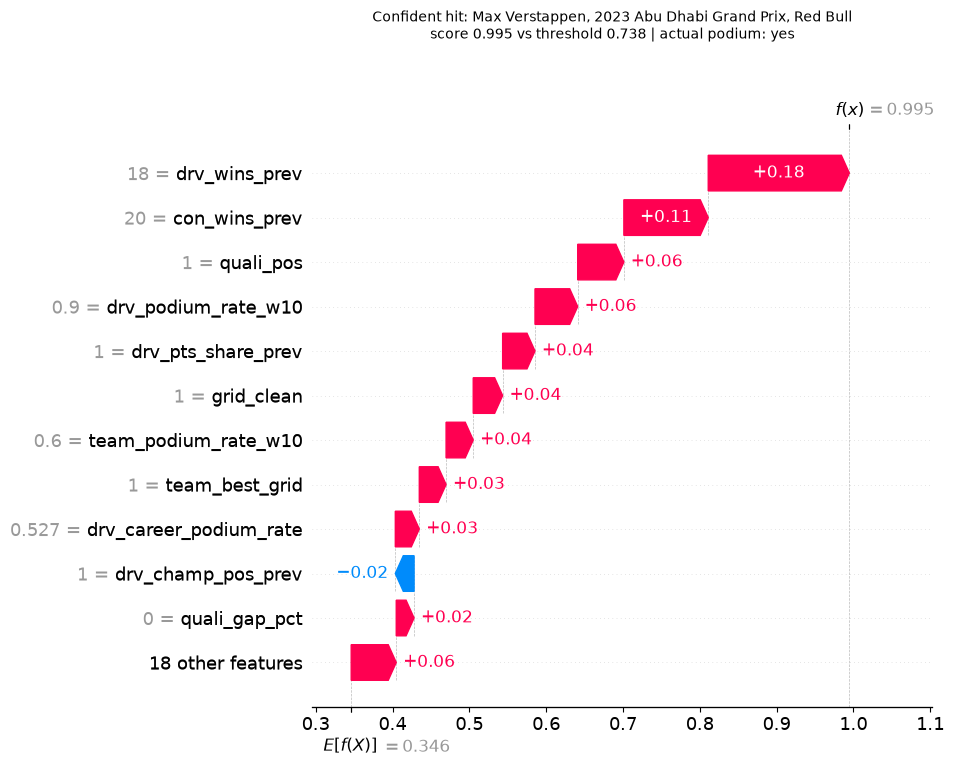

  Confident hit: pushed UP by drv_wins_prev (18: +0.184), con_wins_prev (20: +0.110), quali_pos (1: +0.060)
                 pushed DOWN by drv_champ_pos_prev (1: -0.024), con_champ_pos_prev (1: -0.012), season_progress (1: -0.012)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_missed_podium.png


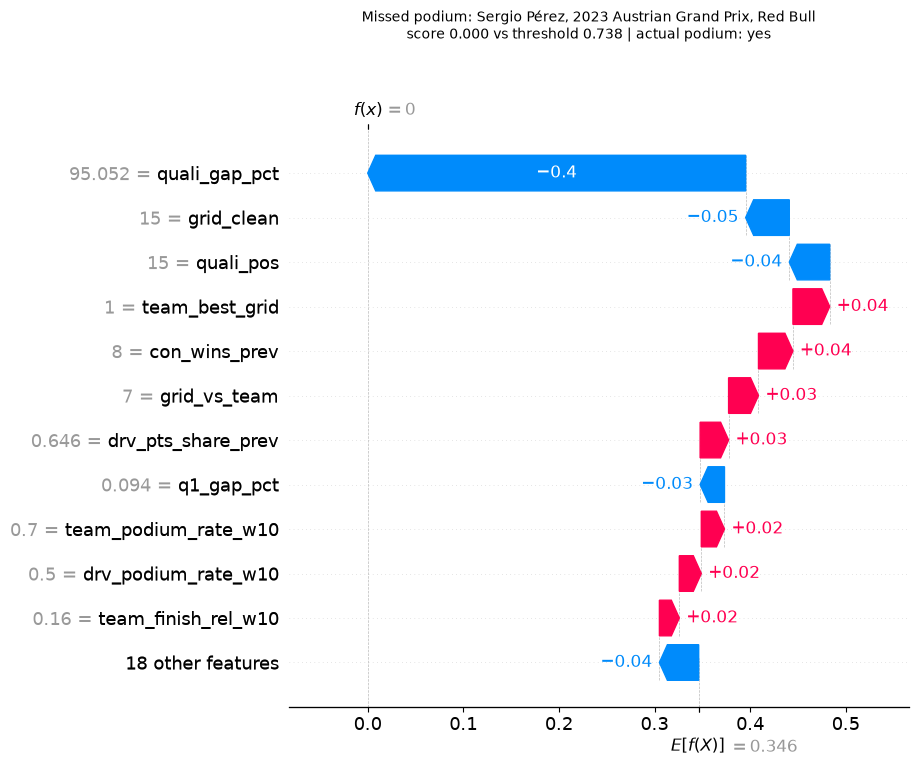

  Missed podium: pushed UP by team_best_grid (1: +0.038), con_wins_prev (8: +0.036), grid_vs_team (7: +0.031)
                 pushed DOWN by quali_gap_pct (95.1: -0.395), grid_clean (15: -0.046), quali_pos (15: -0.042)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_false_alarm.png


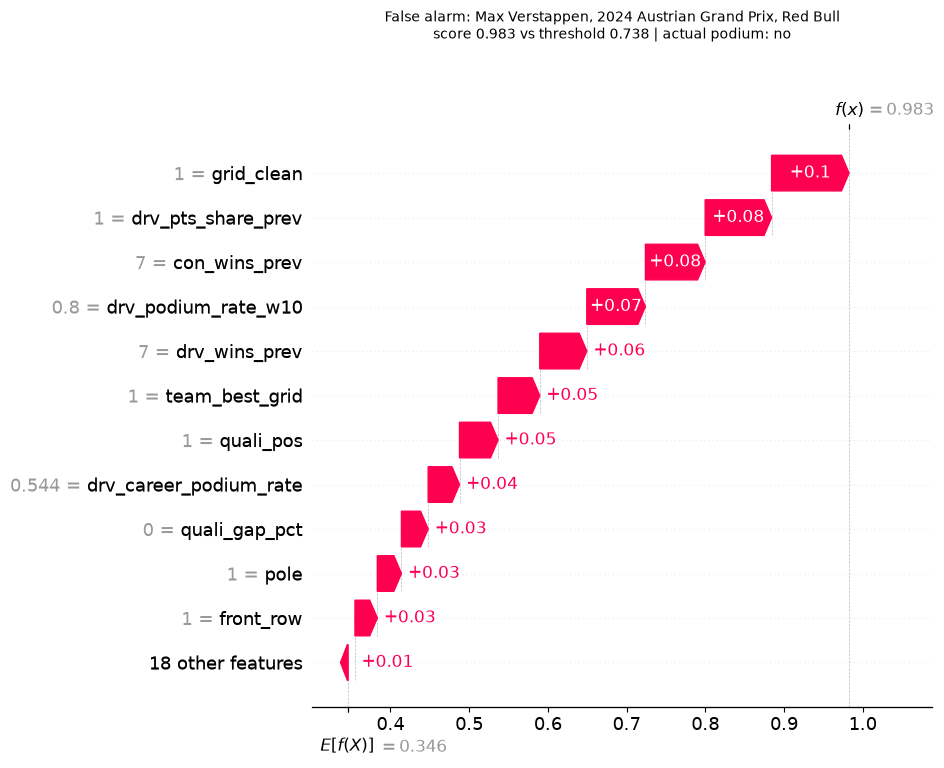

  False alarm: pushed UP by grid_clean (1: +0.098), drv_pts_share_prev (1: +0.084), con_wins_prev (7: +0.076)
               pushed DOWN by drv_champ_pos_prev (1: -0.026), con_champ_pos_prev (1: -0.023), drv_finish_rel_w10 (0.175: -0.011)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_borderline.png


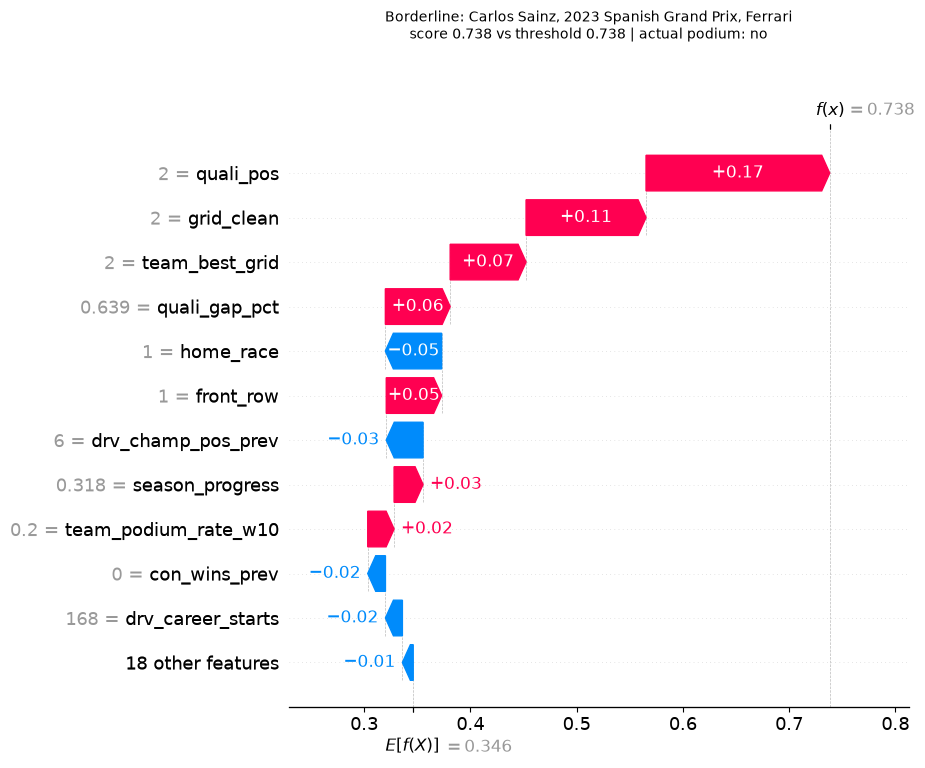

  Borderline: pushed UP by quali_pos (2: +0.173), grid_clean (2: +0.113), team_best_grid (2: +0.071)
              pushed DOWN by home_race (1: -0.053), drv_champ_pos_prev (6: -0.035), con_wins_prev (0: -0.017)



In [26]:
def shap_top(i, k=3):
    v = pd.Series(sv.values[i], index=FEATURES); pos = v.sort_values(ascending=False).head(k); neg = v.sort_values().head(k)
    fmt = lambda s: ", ".join(f"{f} ({ex.loc[i, f]:.3g}: {x:+.3f})" if not pd.isna(ex.loc[i, f]) else f"{f} (missing: {x:+.3f})" for f, x in s.items())
    return fmt(pos), fmt(neg)

for name, i in CASES.items():
    plt.figure(); shap.plots.waterfall(sv[i], max_display=12, show=False); fig = plt.gcf()
    fig.suptitle(f"{name}: {case_label(i)}\nscore {p_ex[i]:.3f} vs threshold {thr:.3f} | actual podium: {'yes' if y_ex[i] else 'no'}", y=1.04, fontsize=10)
    save_fig(fig, f"shap_waterfall_{name.lower().replace(' ', '_')}.png")
    up, down = shap_top(i)
    print(f"  {name}: pushed UP by {up}\n  {' ' * len(name)}  pushed DOWN by {down}\n")

### 15.7.2 LIME

LIME perturbs the row many times (here 5,000), asks the model to score the perturbed rows, and fits a small weighted linear model on *binned* feature values. Its weights say which bins of which features pushed *this* score up or down in the neighbourhood of the row.

Practical differences from SHAP that matter when comparing them:
- LIME cannot take missing values, so the few missing inputs are filled with the training median (binary flags: most frequent value) before it runs. For cases with missing features this slightly changes what is explained; the count is in the case table above.
- LIME is random. The stability check below reruns it with different seeds.
- LIME weights are relative to its own local model, not to the SHAP reference average, so only the **direction and ranking** are compared with SHAP, not the sizes.
- `R2` is the fit of LIME's local model to the network around the row. A low value means the network is not well approximated by a simple model there, and the LIME weights should be trusted less.

In [27]:
LIME_RES, LIME_CMP = {}, []
if HAVE_LIME:
    fill = pd.concat([train[CONTINUOUS].median(), train[BINARY].mode().iloc[0]])
    lime_bg = bg_pool[FEATURES].fillna(fill).to_numpy(float)
    cat_idx = [FEATURES.index(b) for b in BINARY]
    def lime_run(x, seed):
        le = LimeTabularExplainer(lime_bg, feature_names=FEATURES, categorical_features=cat_idx, class_names=["no podium", "podium"],
                                  mode="classification", discretize_continuous=True, random_state=seed)
        e = le.explain_instance(x, xai_proba, num_features=10, num_samples=LIME_SAMPLES, labels=(1,))
        sc = e.score; sc = sc.get(1) if isinstance(sc, dict) else sc
        return e, float(sc) if sc is not None else np.nan
    t0 = time.time()
    for name, i in CASES.items():
        x = ex.loc[i, FEATURES].fillna(fill).to_numpy(float)
        e, r2 = lime_run(x, SEED)
        m = e.as_map()[1]; desc = dict(zip([a for a, _ in m], [d for d, _ in e.as_list(label=1)]))
        lime_w = pd.Series({FEATURES[a]: w for a, w in m}); lime_desc = {FEATURES[a]: desc[a] for a, _ in m}
        # stability: top-5 features across different LIME seeds
        tops = [set(lime_w.abs().sort_values(ascending=False).head(5).index)]
        for s in range(1, LIME_SEEDS):
            ws = pd.Series({FEATURES[a]: w for a, w in lime_run(x, SEED + s)[0].as_map()[1]}); tops.append(set(ws.abs().sort_values(ascending=False).head(5).index))
        jac = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(tops, 2)])
        shap_v = pd.Series(sv.values[i], index=FEATURES)
        s_top5, l_top5 = set(shap_v.abs().sort_values(ascending=False).head(5).index), set(lime_w.abs().sort_values(ascending=False).head(5).index)
        common = lime_w.index
        LIME_RES[name] = dict(weights=lime_w, desc=lime_desc, r2=r2)
        LIME_CMP.append(dict(case=name, lime_local_R2=r2, top5_overlap_shap_lime=len(s_top5 & l_top5),
                             sign_agreement_on_lime_top10=float(np.mean(np.sign(lime_w[common]) == np.sign(shap_v[common]))),
                             spearman_signed_on_lime_top10=spearmanr(lime_w[common], shap_v[common]).statistic,
                             lime_top5_stability_jaccard=jac))
    print(f"LIME for {len(CASES)} cases x {LIME_SEEDS} seeds in {time.time()-t0:.0f}s")
    lime_cmp = pd.DataFrame(LIME_CMP); display(lime_cmp.round(3))
else:
    print("LIME not installed: skipped. (pip install lime)")

LIME for 4 cases x 5 seeds in 1s


,case,lime_local_R2,top5_overlap_shap_lime,sign_agreement_on_lime_top10,spearman_signed_on_lime_top10,lime_top5_stability_jaccard
0,Confident hit,0.368,3,0.9,0.539,0.440
1,Missed podium,0.287,3,0.9,0.758,0.619
2,False alarm,0.369,4,0.9,0.855,0.440
3,Borderline,0.287,4,0.9,0.842,0.629


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_confident_hit.png


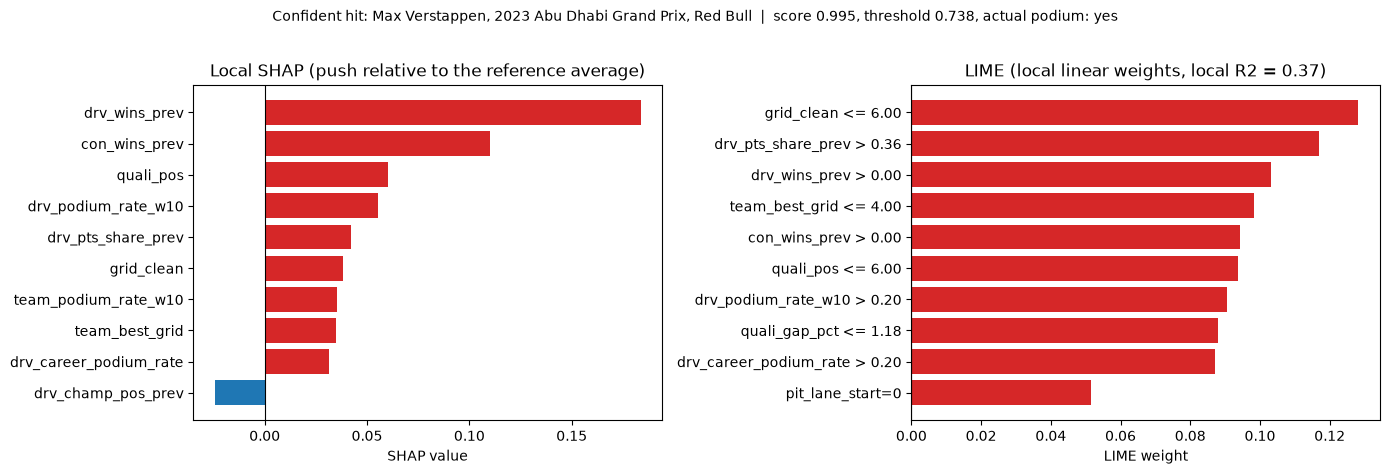

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_missed_podium.png


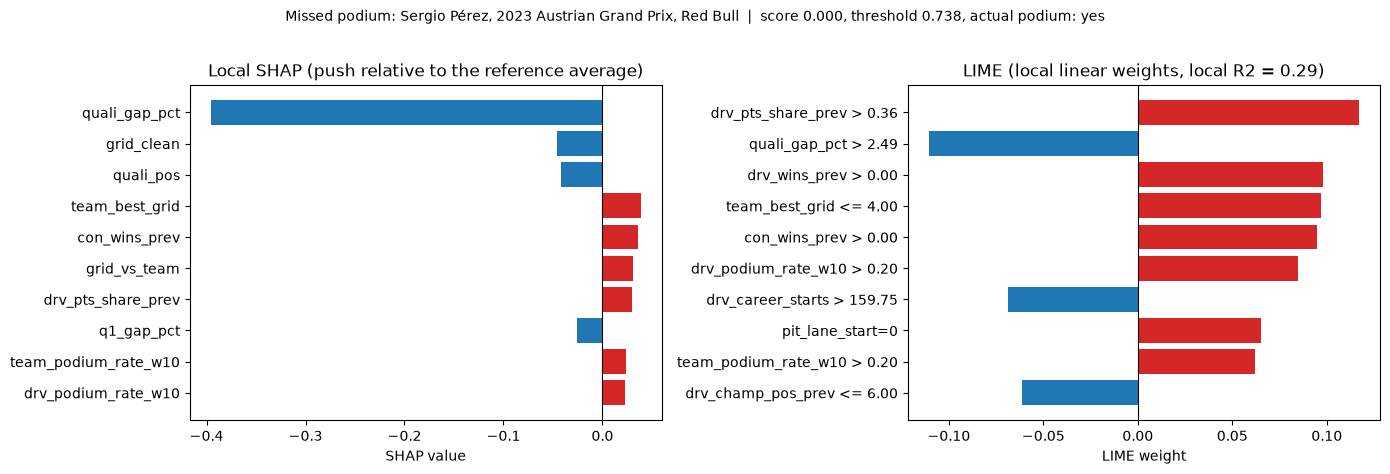

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_false_alarm.png


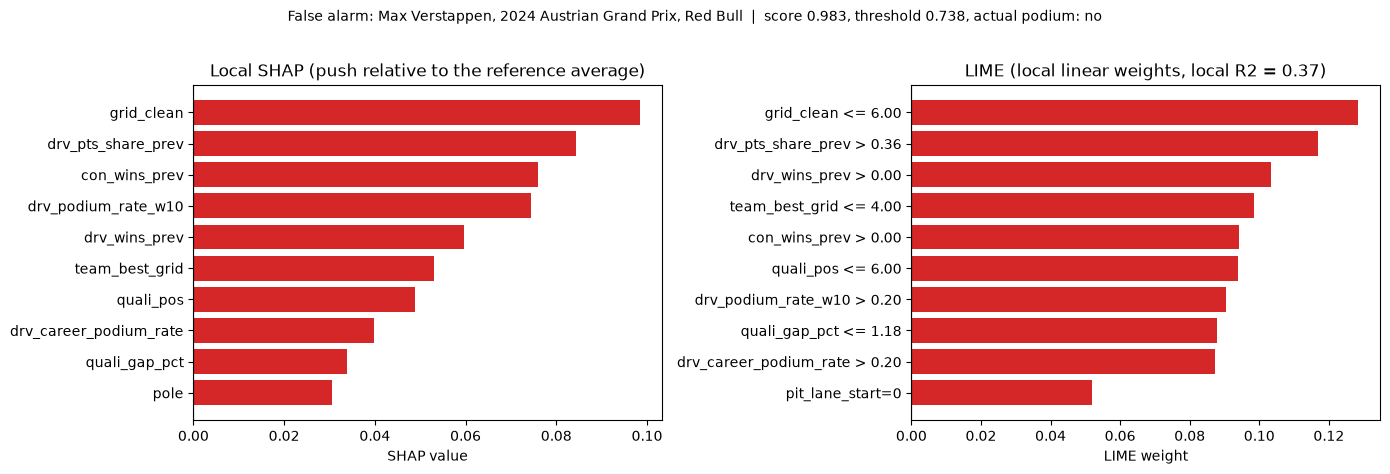

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_borderline.png


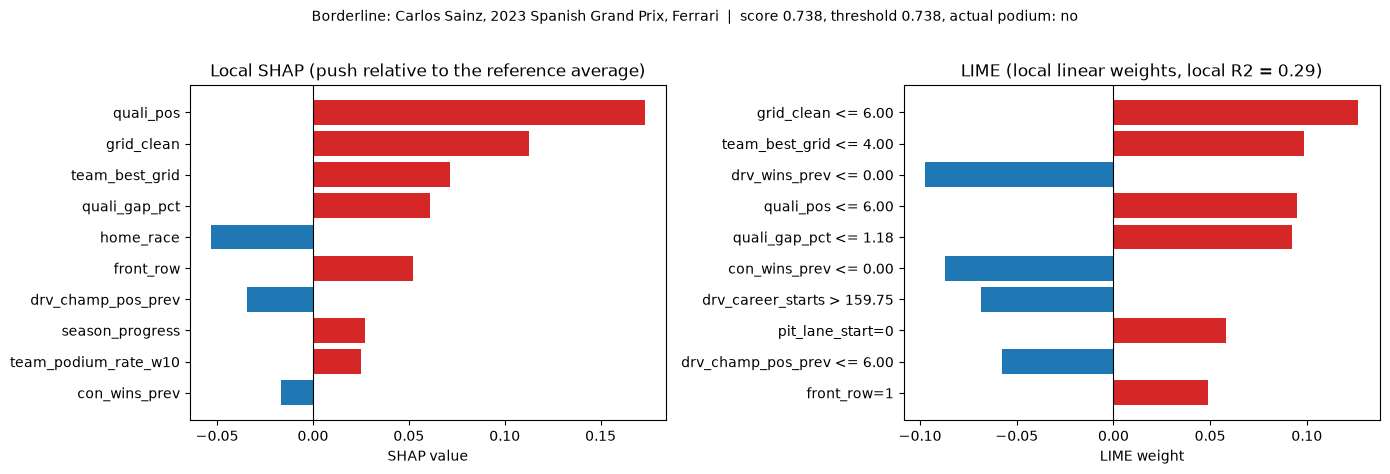

In [28]:
# SHAP and LIME side by side for each case (top 10 features of each)
if HAVE_LIME:
    for name, i in CASES.items():
        sv_i = pd.Series(sv.values[i], index=FEATURES); s10 = sv_i.reindex(sv_i.abs().sort_values(ascending=False).head(10).index)[::-1]
        lw = LIME_RES[name]["weights"]; l10 = lw.reindex(lw.abs().sort_values(ascending=False).index)[::-1]
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        axes[0].barh(s10.index, s10.values, color=["tab:red" if v > 0 else "tab:blue" for v in s10.values]); axes[0].axvline(0, color="k", lw=0.8)
        axes[0].set_title("Local SHAP (push relative to the reference average)"); axes[0].set_xlabel("SHAP value")
        axes[1].barh([LIME_RES[name]["desc"][f] for f in l10.index], l10.values, color=["tab:red" if v > 0 else "tab:blue" for v in l10.values]); axes[1].axvline(0, color="k", lw=0.8)
        axes[1].set_title(f"LIME (local linear weights, local R2 = {LIME_RES[name]['r2']:.2f})"); axes[1].set_xlabel("LIME weight")
        fig.suptitle(f"{name}: {case_label(i)}  |  score {p_ex[i]:.3f}, threshold {thr:.3f}, actual podium: {'yes' if y_ex[i] else 'no'}", fontsize=10, y=1.02)
        fig.tight_layout(); save_fig(fig, f"local_shap_vs_lime_{name.lower().replace(' ', '_')}.png")

### 15.7.3 The same four rows under every verified model

Each verified model scores the same driver-race rows. Differences show where models disagree about a row. Pushes are SHAP values in each model's own units, so only the **names and order** of the leading features are comparable.

In [29]:
rows = []
for name, i in CASES.items():
    for k, m in MODELS.items():
        sc = float(predict_p(m, ex.iloc[[i]])[0])
        v = pd.Series(sv.values[i], index=FEATURES) if k == EXPLAIN_KEY else (OTHER_SHAP[k]["values"].iloc[i] if k in OTHER_SHAP else None)
        up = ", ".join(v.sort_values(ascending=False).head(3).index) if v is not None else "n/a"
        down = ", ".join(v.sort_values().head(3).index) if v is not None else "n/a"
        rows.append(dict(case=name, row=case_label(i), model=LABEL[k], score=round(sc, 3), threshold=round(THRESHOLD[k], 3), predicts_podium=sc >= THRESHOLD[k],
                         actual_podium=int(y_ex[i]), top3_push_up=up, top3_push_down=down))
CASE_MODELS = pd.DataFrame(rows)
for name in CASES:
    print(f"\n{name}: {case_label(CASES[name])}"); display(CASE_MODELS[CASE_MODELS["case"] == name].drop(columns=["case", "row"]).reset_index(drop=True))


Confident hit: Max Verstappen, 2023 Abu Dhabi Grand Prix, Red Bull


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.982,0.670,True,1,"grid_clean, drv_wins_prev, team_best_grid","q1_gap_pct, season_progress, con_wins_prev"
1,Shallow NN,0.995,0.738,True,1,"drv_wins_prev, con_wins_prev, quali_pos","drv_champ_pos_prev, con_champ_pos_prev, season_progress"
2,Random forest,0.974,0.713,True,1,"grid_clean, team_best_grid, drv_podium_rate_w10","season_progress, circuit_front_row_podium_rate, grid_minus_quali"
3,XGBoost,0.968,0.720,True,1,"grid_clean, team_best_grid, quali_gap_pct","season_progress, circuit_front_row_podium_rate, drv_circuit_prev_starts"



Missed podium: Sergio Pérez, 2023 Austrian Grand Prix, Red Bull


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.000,0.670,False,1,"team_best_grid, team_finish_rel_w10, team_podium_rate_w10","quali_gap_pct, grid_clean, quali_pos"
1,Shallow NN,0.000,0.738,False,1,"team_best_grid, con_wins_prev, grid_vs_team","quali_gap_pct, grid_clean, quali_pos"
2,Random forest,0.562,0.713,False,1,"drv_podium_rate_w10, team_best_grid, team_podium_rate_w10","grid_clean, grid_vs_team, front_row"
3,XGBoost,0.511,0.720,False,1,"team_podium_rate_w10, drv_podium_rate_w10, team_best_grid","grid_clean, quali_gap_pct, grid_vs_team"



False alarm: Max Verstappen, 2024 Austrian Grand Prix, Red Bull


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.976,0.670,True,0,"grid_clean, team_best_grid, drv_podium_rate_w10","q1_gap_pct, circuit_front_row_podium_rate, drv_circuit_prev_starts"
1,Shallow NN,0.983,0.738,True,0,"grid_clean, drv_pts_share_prev, con_wins_prev","drv_champ_pos_prev, con_champ_pos_prev, drv_finish_rel_w10"
2,Random forest,0.969,0.713,True,0,"grid_clean, team_best_grid, drv_podium_rate_w10","circuit_front_row_podium_rate, drv_circuit_prev_starts, season_progress"
3,XGBoost,0.965,0.720,True,0,"grid_clean, team_best_grid, quali_gap_pct","age, drv_circuit_prev_starts, circuit_front_row_podium_rate"



Borderline: Carlos Sainz, 2023 Spanish Grand Prix, Ferrari


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.792,0.670,True,0,"grid_clean, team_best_grid, quali_pos","q1_gap_pct, drv_career_podium_rate, home_race"
1,Shallow NN,0.738,0.738,False,0,"quali_pos, grid_clean, team_best_grid","home_race, drv_champ_pos_prev, con_wins_prev"
2,Random forest,0.775,0.713,True,0,"grid_clean, team_best_grid, front_row","drv_podium_rate_w10, con_wins_prev, drv_wins_prev"
3,XGBoost,0.836,0.720,True,0,"grid_clean, team_best_grid, quali_gap_pct","drv_podium_rate_w10, drv_career_podium_rate, q1_gap_pct"


## 15.8 Conclusions (computed from the results above), limitations, saved files

The paragraph printed by the next cell is generated from the tables and checks above, so every number in it matches the figures. Copy it into the report and add the domain reading of the top features yourself (why a front-row start or a strong team record would matter in Formula 1). **It describes the model's behaviour, not causes.**

In [30]:
pi_t = PI["test"].sort_values("pr_auc_drop", ascending=False); top3p = pi_t.head(3)
lines = []
ok_models = STATUS[STATUS["verdict"].isin(["PASS", "CLOSE"])]
lines.append("Models analysed (each reproduced its saved validation and test predictions, max difference shown): " + "; ".join(f"{r.model} via {r.obtained_by} ({max(r.val_max_diff, r.test_max_diff):.0e})" for r in ok_models.itertuples())
             + (f". NOT analysed because they could not be reproduced: {', '.join(STATUS[STATUS['verdict'] == 'FAIL']['model'])}." if (STATUS["verdict"] == "FAIL").any() else "."))
lines.append(f"Model explained: {LABEL[EXPLAIN_KEY]} (test PR-AUC {base_scores['test']['pr_auc']:.3f}, validation {base_scores['validation']['pr_auc']:.3f}; "
             f"rank {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)} on test PR-AUC among the saved models).")
lines.append("Permutation importance (test): the three features whose shuffling hurts PR-AUC most are "
             + ", ".join(f"{r.feature} ({r.pr_auc_drop:.3f})" for r in top3p.itertuples()) + f". {int(pi_t['reliable'].sum())} of {len(pi_t)} features are reliably used (mean drop above 2 standard deviations); "
             f"the rest could be shuffled without a detectable loss.")
vt_word = "agree closely" if AG_VT["spearman_top"] >= 0.8 else "agree partly" if AG_VT["spearman_top"] >= 0.5 else "disagree"
lines.append(f"The validation and test rankings {vt_word} (Spearman {AG_VT['spearman_top']:.2f} over the top-10 union, {AG_VT['overlap_top']} of the top 10 shared).")
g1 = GPI["test"].iloc[0]; lines.append(f"By feature group, shuffling '{g1.group}' costs the most PR-AUC ({g1.pr_auc_drop:.3f}); in descending order: " + ", ".join(f"{r.group} ({r.pr_auc_drop:.3f})" for r in GPI["test"].itertuples()) + ".")
lines.append("SHAP (test rows): the largest mean |SHAP| belong to " + ", ".join(f"{r.feature} ({r.mean_abs_shap:.3f}, {r.share_of_total:.0%} of the total)" for r in shap_tab.head(3).itertuples())
             + f". By group the largest is '{group_shap.iloc[0]['group']}' ({group_shap.iloc[0]['share_of_total']:.0%} of total group SHAP).")
ps_word = "rank features similarly" if AG_PS["spearman_top"] >= 0.8 else "agree only partly on the ranking" if AG_PS["spearman_top"] >= 0.5 else "disagree on the ranking"
lines.append(f"Permutation importance and SHAP {ps_word} (Spearman {AG_PS['spearman_top']:.2f} over the top-10 union, {AG_PS['overlap_top']} of the top 10 shared)" + ("." if ps_word == "rank features similarly" else "; a feature ranked much higher by SHAP than by permutation is one the model pushes on without that push improving test accuracy much."))
lines.append(f"The SHAP ranking is {'robust' if BG_MIN_RHO >= 0.85 else 'moderately sensitive' if BG_MIN_RHO >= 0.7 else 'sensitive'} to the reference data (lowest pairwise Spearman across three references: {BG_MIN_RHO:.2f}; robust at 0.85 or above).")
lines.append("Other verified models (permutation importance, test): " + "; ".join(f"{r['model']} top 3 = {r['top3_by_permutation']}" for r in summ) + ".")
if AG_OTHERS:
    lines.append("Exact SHAP on the other models gives rankings that " + "; ".join(f"for {k} {'agree with' if v['spearman_top'] >= 0.8 else 'agree partly with' if v['spearman_top'] >= 0.5 else 'differ from'} {LABEL[EXPLAIN_KEY]} (Spearman {v['spearman_top']:.2f} over the top-10 union, {v['overlap_top']} of the top 10 shared)" for k, v in AG_OTHERS.items()) + ".")
if SEED_AGREE is not None:
    lines.append(f"Across three retrained network seeds (and the saved model) the permutation rankings have pairwise Spearman between {SEED_AGREE['spearman_top'].min():.2f} and {SEED_AGREE['spearman_top'].max():.2f} over the top-10 union, "
                 f"and share at least {int(SEED_AGREE['overlap_top'].min())} of their top 10 features: a network explanation is {'stable' if SEED_AGREE['spearman_top'].min() >= 0.8 else 'only moderately stable' if SEED_AGREE['spearman_top'].min() >= 0.5 else 'not stable'} across seeds.")
if HAVE_LIME and LIME_CMP:
    lc = pd.DataFrame(LIME_CMP)
    lines.append(f"Local: SHAP and LIME share on average {lc['top5_overlap_shap_lime'].mean():.1f} of their top-5 features across the four cases, agree in sign on {lc['sign_agreement_on_lime_top10'].mean():.0%} of LIME's top-10 features, "
                 f"LIME's local R2 averages {lc['lime_local_R2'].mean():.2f} and its top-5 set is {lc['lime_top5_stability_jaccard'].mean():.0%} stable across seeds (Jaccard).")
lines.append("None of these results are causal effects: a feature is important here only in the sense that this fitted model's scores depend on it.")
CONCLUSIONS = "\n\n".join(lines); print(CONCLUSIONS)

Models analysed (each reproduced its saved validation and test predictions, max difference shown): Logistic regression via saved .joblib (4e-16); Shallow NN via saved .joblib (2e-16); Random forest via saved .joblib (6e-16); XGBoost via saved .joblib (6e-08).

Model explained: Shallow NN (test PR-AUC 0.689, validation 0.748; rank 4 of 4 on test PR-AUC among the saved models).

Permutation importance (test): the three features whose shuffling hurts PR-AUC most are quali_pos (0.072), grid_clean (0.060), team_best_grid (0.028). 8 of 29 features are reliably used (mean drop above 2 standard deviations); the rest could be shuffled without a detectable loss.

The validation and test rankings disagree (Spearman 0.13 over the top-10 union, 6 of the top 10 shared).

By feature group, shuffling 'grid' costs the most PR-AUC (0.178); in descending order: grid (0.178), standings (0.080), qualifying (0.072), context (0.011), constructor_form (0.011), driver_form (0.010), circuit_history (-0.006).

S

### Limitations to state in the report

1. **Not causal.** Importance, SHAP values and LIME weights describe how the fitted model maps inputs to scores. A high-importance feature may be a proxy for something unmeasured (car pace, tyre strategy), and nothing here supports the claim that changing it would change a race result.
2. **Correlated features.** Starting slot, qualifying position, team form and standings carry overlapping information. Single-feature importances split or hide credit; the group-level results are the safer thing to quote.
3. **Unrealistic perturbations.** Permutation importance, permutation SHAP and LIME all evaluate the model on feature combinations that never occur (a pole sitter with an impossible team record). Model behaviour in those regions can be arbitrary, so very small importances should not be over-read.
4. **Reference data and era.** SHAP is relative to a reference population (hybrid-era training rows). The test seasons use new regulations; the model was trained mostly on earlier cars, so explanations describe how an earlier-era model scores new-era rows, not how the new era works.
5. **Scores are not calibrated.** Class up-weighting inflates scores; SHAP magnitudes are in score units.
6. **One network, one seed.** The saved network is a single draw; the seed check bounds how much that matters, but it is not an interval around the true relationship.
7. **Small test set.** About three seasons of races. Importance differences of a few thousandths of PR-AUC are within the spread shown by the error bars.
8. **LIME** is stochastic, is fitted on binned values, and had its few missing inputs filled; it is shown as a second opinion on individual cases, not as ground truth.
9. **Explaining the final model, not the best test model.** If the final model chosen on validation is not the best on test, say so explicitly; the cross-model analyses in 15.3.2 and 15.6.2 are there so the conclusions do not hang on one model.

In [31]:
# ---- save everything the report needs -----------------------------------------------------------------------------
def save_tab(df, name, index=False):
    p = os.path.join(TAB_DIR, name); df.to_csv(p, index=index); return name
saved = [save_tab(PI_TABLE, "permutation_importance_features.csv"), save_tab(GROUP_PI_TABLE, "permutation_importance_groups.csv"),
         save_tab(cross_mat.reset_index().rename(columns={"index": "feature"}), "permutation_importance_cross_model.csv"),
         save_tab(shap_tab, "shap_global_importance.csv"), save_tab(group_shap, "shap_group_importance.csv"),
         save_tab(cmp.reset_index().rename(columns={"index": "feature"}), "permutation_vs_shap.csv"),
         save_tab(bg_imp.reset_index().rename(columns={"index": "feature"}), "shap_background_sensitivity.csv"),
         save_tab(case_df, "local_cases.csv")]
if SEED_RANK is not None: saved.append(save_tab(SEED_RANK.reset_index().rename(columns={"index": "feature"}), "permutation_importance_seeds.csv"))
if HAVE_LIME and LIME_CMP: saved.append(save_tab(pd.DataFrame(LIME_CMP), "local_shap_vs_lime.csv"))
saved += [save_tab(STATUS, "model_verification.csv"), save_tab(OTHER_SHAP_STATUS, "other_models_shap_status.csv"), save_tab(CASE_MODELS, "local_cases_all_models.csv"),
          save_tab(SHAP_CROSS.reset_index().rename(columns={"index": "feature"}), "shap_cross_model.csv")]
for k_, o_ in OTHER_SHAP.items():
    o_["values"].assign(resultId=ex["resultId"].to_numpy()).to_parquet(os.path.join(TAB_DIR, f"shap_values_test_{k_}.parquet"), index=False); saved.append(f"shap_values_test_{k_}.parquet")
shap_df = pd.DataFrame(sv.values, columns=FEATURES); shap_df.insert(0, "resultId", ex["resultId"].to_numpy()); shap_df["base_value"] = sv.base_values; shap_df["model_score"] = p_ex
shap_df.to_parquet(os.path.join(TAB_DIR, "shap_values_test.parquet"), index=False); saved.append("shap_values_test.parquet")
json.dump(dict(explained_model=EXPLAIN_KEY, label=LABEL[EXPLAIN_KEY], threshold=thr, reference_rows=len(bg_df), shap_permutations=N_PERMUTATIONS,
               additivity_max_error=add_err, base_value=base_val, model_verification=STATUS.drop(columns="attempts").to_dict("records"), conclusions=CONCLUSIONS.split("\n\n")), open(os.path.join(TAB_DIR, "xai_summary.json"), "w"), indent=2)
saved.append("xai_summary.json")
print("tables saved to", TAB_DIR, "->", saved)
print("figures saved to", FIG_DIR, "->", sorted(os.listdir(FIG_DIR)))

tables saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs -> ['permutation_importance_features.csv', 'permutation_importance_groups.csv', 'permutation_importance_cross_model.csv', 'shap_global_importance.csv', 'shap_group_importance.csv', 'permutation_vs_shap.csv', 'shap_background_sensitivity.csv', 'local_cases.csv', 'permutation_importance_seeds.csv', 'local_shap_vs_lime.csv', 'model_verification.csv', 'other_models_shap_status.csv', 'local_cases_all_models.csv', 'shap_cross_model.csv', 'shap_values_test_logreg.parquet', 'shap_values_test_rf.parquet', 'shap_values_test_xgb.parquet', 'shap_values_test.parquet', 'xai_summary.json']
figures saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai -> ['local_shap_vs_lime_borderline.png', 'local_shap_vs_lime_confident_hit.png', 'local_shap_vs_lime_false_alarm.png', 'local_shap_vs_lime_missed_podium.png', 'perm_importance_cross_model.png', 'perm_imp